# 79. Hard-fault-focused joint rollout fine-tuning

Initialize from **78 best**, not the previous 79 run. Default: detached 4-window rollouts. The model and ordinary joint losses are preserved. We modify two independent things: (1) initial fault sampling, and (2) per-sensor classification loss weighting on actual current rollout states. A large initial error is a candidate, not automatically a hard example. Hard = true error above the configured minimum AND regression correction at or below the operational threshold. Recompute after every update. No GT is used to alter the rollout updates.

Validation remains unweighted and uses the original exhaustive case distribution. A separate fixed-reference bank replays states generated by frozen 78, evaluates each model on exactly those states, and measures hard recall and healthy false alarms. The new run directory avoids overwriting the original 79. Stochastic/full runs independently restart from 78. No additional repository modules required.

## 1. Imports

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.models.pooled_calibration_classifier_head import PooledCalibrationClassifierHead
from dataclasses import dataclass
from torch import nn
import torch.nn.functional as F
import gc
import copy
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Configuration

In [4]:
ORIGINAL_CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_joint_regr_class_6d_006.1_002.27' / 'best.pt'
RUN_NAME = 'kaist_joint_regr_class_6d_007.2_hard_rollout'
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESUME_TRAINING = False
RUN_STOCHASTIC_TEST = True
RUN_STOCHASTIC_CHECKPOINT_EVALUATION = True
RUN_FULL_TRAINING = True
RUN_DETAILED_EVALUATION = True
RUN_TEST_EVALUATION = False
RUN_CONTROLLED_SWEEP = True
RUN_ROLLOUT_EVALUATION = True  # Optional chronological test after full evaluation.

RANDOM_SEED = 79_0027
TRAIN_AUG_SEED, VALIDATION_AUG_SEED, TEST_AUG_SEED = 79_1001, 79_2002, 79_3003
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
TRAIN_NAMES = ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
VAL_NAMES = ('Urban26', 'Urban28')
TEST_NAMES = ('Urban38', 'Urban39')
assert len(set(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)) == len(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 1
NUM_WORKERS = 0  # No DataLoader workers in the rollout sampler.
TRAIN_ROLLOUT_WINDOWS = 4
DETACH_ROLLOUT = True
TRAIN_ROLLOUT_STRIDE = None  # None = length (non-overlapping blocks); 1 = sliding starts.
ROLLOUT_UPDATE_TIME = True
# All steps receive equal supervision; optionally upweight the last post-update residual.
ENDPOINT_LOSS_WEIGHT = 0.0
MONITOR_ROLLOUTS_PER_SEQUENCE = 24
ASSESS_ROLLOUTS_PER_SEQUENCE = 48
STOCHASTIC_STEPS = 500
STOCHASTIC_PHYSICAL_ROLLOUTS = 64
STOCHASTIC_MONITOR_ROLLOUTS_PER_SEQUENCE = 8
STOCHASTIC_ASSESS_ROLLOUTS_PER_SEQUENCE = 12
STOCHASTIC_PRINT_EVERY = 25
RUN_STOCHASTIC_ROLLOUT_ASSESSMENT = True
assert TRAIN_ROLLOUT_WINDOWS >= 1 and (TRAIN_ROLLOUT_STRIDE is None or TRAIN_ROLLOUT_STRIDE >= 1)
assert GRADIENT_ACCUMULATION_STEPS >= 1 and ENDPOINT_LOSS_WEIGHT >= 0

TRAIN_CASES_PER_PHYSICAL = 4
PHYSICAL_WINDOWS_PER_UPDATE = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS // TRAIN_CASES_PER_PHYSICAL
NUM_EPOCHS = 200
MONITOR_WINDOWS_PER_VAL_SEQUENCE = 64
DETAILED_WINDOWS_PER_SEQUENCE = 250
SWEEP_WINDOWS_PER_SEQUENCE = 24
SWEEP_AXIS_REPEATS = 2
SWEEP_ANGLES_DEG = (0., 1., 2., 3., 3.5, 4., 5., 7.5, 10., 15., 20., 30., 45., 60., 75., 90., 120., 150., 179.)
ROLLOUT_STARTS_PER_SEQUENCE = 4
ROLLOUT_NUM_WINDOWS = 12
ROLLOUT_ANGLES_DEG = (0., 5., 10., 20., 45., 90., 150., 179.)
ROLLOUT_TIME_FAULT_MS = (50., 100.)

# All parameters are pretrained; use a conservative classifier LR too.
LR_TRANSFORMER, LR_POOLER, LR_SHARED_MLP = 1e-5, 2e-5, 2e-5
LR_REGRESSION_HEAD, LR_CLASSIFIER_HEAD = 2e-5, 4e-5
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS = 0.5, 8
PRINT_EVERY_BATCHES = 500

# Loss weights: both regression terms and all three BCE terms are active.
REGRESSION_LOSS_WEIGHT, CLASSIFICATION_LOSS_WEIGHT = 1.0, 1.0
REG_ROT_WEIGHT, REG_TIME_WEIGHT = 1.0, 1.0
REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS = 60.0, 50.0
JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT = 1.0, 1.0, 1.0
TIME_POS_WEIGHT = 1.0
# Penalize deterioration relative to the original regressor when choosing best.pt.
REGRESSION_SELECTION_PENALTY = 0.5
GT_ROT_TOL_DEG, GT_TAU_TOL_MS = 5.0, 10.0
DEFAULT_DECISION_THRESHOLD = 0.5
PROBABILITY_THRESHOLDS = np.linspace(0.0, 1.0, 101)
REG_ROT_THRESHOLDS_DEG = (0.5, 1., 2., 3., 4., 5., 7.5, 10., 15., 20.)
REG_TIME_THRESHOLDS_MS = (2., 5., 10., 15., 20., 30., 50., 75., 100.)
K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)
FAULT_COUNTS = (0, 1, 2, 3)
FAULT_MODES = ('rotation_only', 'time_only', 'both')
MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED = False
# ----------------------------------------------------------------------
# A. Initial fault SAMPLING (training only; independent of loss weighting)
# ----------------------------------------------------------------------
# Each initial rollout case independently uses ONE branch:
#   standard (1 - HARD_CANDIDATE_FRACTION): K_PROBABILITIES, uniform mode,
#       uniform choice among original magnitude bins, then uniform in bin.
#   candidate (HARD_CANDIDATE_FRACTION): exactly one faulty sensor, rotation
#       only, sensor uniform, axis uniform on sphere, weighted angle bins.
# Candidate != actual hard fault. No rejection sampling / extra forward pass.
HARD_CANDIDATE_FRACTION = 0.35
HARD_CANDIDATE_ROTATION_BINS_DEG = ((5., 20.), (20., 45.), (45., 90.), (90., 150.), (150., 179.))
HARD_CANDIDATE_BIN_PROBABILITIES = (0.10, 0.10, 0.15, 0.25, 0.40)
# Set fraction=0 for the original sampling distribution (weighting-only ablation).

# ----------------------------------------------------------------------
# B. Actual hard-example LOSS WEIGHTING (training only, each sensor/step)
# ----------------------------------------------------------------------
# GT labels stay at 3 deg / 10 ms. A hard positive is a real fault with
# a SMALL predicted correction (<= operational threshold).
# 5.0 means exactly 5x, not 1+5. Negatives always retain weight 1.
HARD_ROTATION_POSITIVE_WEIGHT = 5.0
HARD_TIME_POSITIVE_WEIGHT = 1.0  # 1 disables time hard weighting.
HARD_JOINT_POSITIVE_WEIGHT = 1.0  # preserve ordinary joint BCE by default.
HARD_MIN_ROTATION_DEG = 5.0  # increase to e.g. 10 to target larger missed faults.
HARD_MIN_TIME_MS = 10.0
HARD_WEIGHT_START_STEP = 0  # 0 = include initial state; 1 = only self-generated states.
# Use weights normalized by their sum separately per head; no gradient through masks.
# Set all 3 weights=1 for a sampling-only ablation.

# ----------------------------------------------------------------------
# C. Fixed-reference assessment and checkpoint selection
# ----------------------------------------------------------------------
# 78 generates the priors, candidate models only score them. Probe bank uses
# exactly one clean case plus each sensor at each angle, fixed random axis.
HARD_PROBE_ANGLES_DEG = (6., 20., 90., 150., 179.)
HARD_MONITOR_ROLLOUTS_PER_SEQUENCE = 4
HARD_ASSESS_ROLLOUTS_PER_SEQUENCE = 12
HARD_SELECTION_WEIGHT = 0.5  # mix fixed hard recall with ordinary classification AP
HARD_FALSE_ALARM_PENALTY = 0.5  # subtract this * fixed healthy rotation FPR
# The usual first/endpoint regression deterioration penalty is also retained.
assert 0 <= HARD_CANDIDATE_FRACTION <= 1
assert len(HARD_CANDIDATE_ROTATION_BINS_DEG) == len(HARD_CANDIDATE_BIN_PROBABILITIES)
assert np.isclose(sum(HARD_CANDIDATE_BIN_PROBABILITIES), 1.) and min(HARD_CANDIDATE_BIN_PROBABILITIES) >= 0
assert all(0 < lo < hi <= 179. for lo, hi in HARD_CANDIDATE_ROTATION_BINS_DEG)
assert min(HARD_ROTATION_POSITIVE_WEIGHT, HARD_TIME_POSITIVE_WEIGHT, HARD_JOINT_POSITIVE_WEIGHT) >= 1
assert HARD_MIN_ROTATION_DEG >= GT_ROT_TOL_DEG and HARD_MIN_TIME_MS >= GT_TAU_TOL_MS
assert 0 <= HARD_WEIGHT_START_STEP < TRAIN_ROLLOUT_WINDOWS
assert 0 <= HARD_SELECTION_WEIGHT <= 1 and HARD_FALSE_ALARM_PENALTY >= 0
assert HARD_MONITOR_ROLLOUTS_PER_SEQUENCE >= 1 and HARD_ASSESS_ROLLOUTS_PER_SEQUENCE >= 1
assert len(HARD_PROBE_ANGLES_DEG) and all(GT_ROT_TOL_DEG < a <= 179. for a in HARD_PROBE_ANGLES_DEG)
print('Training sampling: standard=', 1-HARD_CANDIDATE_FRACTION, '| large-angle K1 candidate=', HARD_CANDIDATE_FRACTION)
print('Hard BCE multipliers: R/T/J=', HARD_ROTATION_POSITIVE_WEIGHT, HARD_TIME_POSITIVE_WEIGHT, HARD_JOINT_POSITIVE_WEIGHT)
# Notebook 76's ranges, including below-tolerance negatives, not the 500 ms stress range.
ROTATION_BINS_DEG = ((0.2, 1.), (1., 2.), (2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
TIME_BINS_MS = ((2., 10.), (10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.))
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
BEST_CLASSIFICATION_PATH = RUN_DIR / 'best_classification.pt'
BEST_REGRESSION_PATH = RUN_DIR / 'best_regression.pt'
BEST_HARD_PATH = RUN_DIR / 'best_hard.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
STOCHASTIC_BEST_PATH = RUN_DIR / 'stochastic_best.pt'
STOCHASTIC_FINAL_PATH = RUN_DIR / 'stochastic_final.pt'

assert BATCH_SIZE >= TRAIN_CASES_PER_PHYSICAL and BATCH_SIZE % TRAIN_CASES_PER_PHYSICAL == 0
# assert GRADIENT_ACCUMULATION_STEPS >= 1 and STOCHASTIC_STEPS >= 1
assert np.isclose(sum(K_PROBABILITIES), 1) and min(K_PROBABILITIES) >= 0
assert min(REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS) > 0
assert CHECKPOINT_PATH.is_file(), CHECKPOINT_PATH
if hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(RANDOM_SEED)
print('GPU batch:', BATCH_SIZE, '| optimizer batch:', BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS, '| device:', DEVICE)
print('Source joint checkpoint:', CHECKPOINT_PATH)
assert ORIGINAL_CHECKPOINT_PATH.is_file(), ORIGINAL_CHECKPOINT_PATH

def clear_cuda():
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR / name, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

Training sampling: standard= 0.65 | large-angle K1 candidate= 0.35
Hard BCE multipliers: R/T/J= 5.0 1.0 1.0
GPU batch: 32 | optimizer batch: 32 | device: cuda
Source joint checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_joint_regr_class_6d_006.1_002.27/best.pt


## 3. KAIST datasets and chronological rollout banks

In [5]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_kaist_dataset(TRAIN_NAMES)
val_dataset = make_kaist_dataset(VAL_NAMES)
test_dataset = make_kaist_dataset(TEST_NAMES)
for label, dataset in [('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)]:
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS, label
    print(label, 'windows=', len(dataset), '|', dataset.summary())

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED + 25)

# Validation indices are sampled once, then never shuffled between epochs.
# Use explicit split names, do not infer from dataset internal properties if unavailable.
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)

monitor_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, MONITOR_WINDOWS_PER_VAL_SEQUENCE, RANDOM_SEED + 31)
detailed_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 33)
detailed_test_indices = select_spread_indices_by_names(test_dataset, TEST_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 35)
print('Fixed validation monitor:', len(monitor_val_indices), '| detailed validation:', len(detailed_val_indices), '| final test:', len(detailed_test_indices))

train windows= 2006 | KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
validation windows= 418 | KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
test windows= 699 | KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 

In [6]:
def make_rollout_bank(dataset, names, length, stride):
    """Use consecutive indices inside a single sequence, never across sequence boundaries."""
    bank = []
    for name in names:
        available = np.asarray(dataset.window_indices_for_sequence(name), dtype=int)
        if len(available) and not np.all(np.diff(available) == 1):
            raise ValueError(f'Nonconsecutive dataset indices in {name}; inspect the dataset ordering.')
        bank.extend((name, tuple(map(int, available[start:start + length]))) for start in range(0, len(available) - length + 1, stride))
    return bank


def spread_bank(bank, names, count, seed):
    rng = np.random.default_rng(seed)
    selected = []
    for name in names:
        part = [item for item in bank if item[0] == name]
        if not part: raise ValueError(f'No complete rollouts in {name}.')
        n = min(count, len(part))
        edges = np.linspace(0, len(part), n + 1, dtype=int)
        selected.extend(part[int(rng.integers(lo, hi))] for lo, hi in zip(edges[:-1], edges[1:]))
    return selected


train_bank = make_rollout_bank(train_dataset, TRAIN_NAMES, TRAIN_ROLLOUT_WINDOWS, TRAIN_ROLLOUT_STRIDE or TRAIN_ROLLOUT_WINDOWS)
val_bank = make_rollout_bank(val_dataset, VAL_NAMES, TRAIN_ROLLOUT_WINDOWS, TRAIN_ROLLOUT_WINDOWS)
test_bank = make_rollout_bank(test_dataset, TEST_NAMES, TRAIN_ROLLOUT_WINDOWS, TRAIN_ROLLOUT_WINDOWS)
# The stochastic assessment and monitor banks are physically disjoint (not just different fault draws).
stochastic_monitor_bank = []
for name in VAL_NAMES:
    part = [item for item in val_bank if item[0] == name]
    if len(part) < 2: raise ValueError(f'{name} needs at least two non-overlapping complete rollouts for disjoint stochastic monitoring and assessment.')
    stochastic_monitor_bank.extend(spread_bank(part, (name,), min(STOCHASTIC_MONITOR_ROLLOUTS_PER_SEQUENCE, len(part)-1), RANDOM_SEED+41))
monitor_set = set(stochastic_monitor_bank)
stochastic_assessment_bank = spread_bank([item for item in val_bank if item not in monitor_set], VAL_NAMES, STOCHASTIC_ASSESS_ROLLOUTS_PER_SEQUENCE, RANDOM_SEED + 42)
full_monitor_bank = spread_bank(val_bank, VAL_NAMES, MONITOR_ROLLOUTS_PER_SEQUENCE, RANDOM_SEED + 43)
full_assessment_bank = spread_bank(val_bank, VAL_NAMES, ASSESS_ROLLOUTS_PER_SEQUENCE, RANDOM_SEED + 44)
full_test_bank = spread_bank(test_bank, TEST_NAMES, ASSESS_ROLLOUTS_PER_SEQUENCE, RANDOM_SEED + 45)
# Also keep the stochastic one-step calibration and assessment windows disjoint.
stochastic_monitor_indices = np.asarray([idx for _, seq in stochastic_monitor_bank for idx in seq], dtype=int)
stochastic_assessment_indices = np.asarray([idx for _, seq in stochastic_assessment_bank for idx in seq], dtype=int)
assert not set(stochastic_monitor_indices).intersection(stochastic_assessment_indices)
assert train_bank
print(f'Rollout length={TRAIN_ROLLOUT_WINDOWS} | detach={DETACH_ROLLOUT} | train starts={len(train_bank)} | val monitor={len(full_monitor_bank)} | val assessment={len(full_assessment_bank)} | test={len(full_test_bank)}')
print(f'Stochastic monitor/assessment starts: {len(stochastic_monitor_bank)}/{len(stochastic_assessment_bank)}')

Rollout length=4 | detach=True | train starts=499 | val monitor=47 | val assessment=71 | test=96
Stochastic monitor/assessment starts: 16/24


## 4. Geometry and model architecture (unchanged)

In [7]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)

def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))




def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

## 5. Load all parameters from Notebook 78 best checkpoint

In [8]:
@dataclass
class JointCalibrationOutput:
    regression: object
    logits: torch.Tensor
    calibration_keys: tuple

    @property
    def predictions(self):
        return self.regression.predictions


class JointCalibrationModel(nn.Module):
    def __init__(self, config, regressor):
        super().__init__()
        self.regressor = regressor
        self.classifier_head = PooledCalibrationClassifierHead(config.head, shared_feature_dim=config.mlp.output_dim)
        self.feature_dim = config.mlp.output_dim

    def forward(self, tokens):
        captured = []
        handle = self.regressor.mlp_body.register_forward_hook(lambda module, inputs, output: captured.append(output))
        try:
            regression = self.regressor(tokens)
        finally:
            handle.remove()
        keys = tuple(tokens.calibration_keys)
        batch = tokens.x.shape[0]
        shared = getattr(regression, 'shared_features', None)
        if shared is None:
            if len(captured) != 1:
                raise RuntimeError('Expected exactly one shared MLP execution; inspect the local 6D model.')
            shared = captured[0]
        if shared.shape not in ((batch, len(keys), self.feature_dim), (batch * len(keys), self.feature_dim)):
            raise ValueError(f'Unexpected shared feature shape {shared.shape}')
        flat = self.classifier_head(shared.reshape(batch * len(keys), self.feature_dim))
        logits = torch.cat((flat.unreliable_logit, flat.rotation_fault_logit, flat.time_fault_logit), dim=-1).reshape(batch, len(keys), 3)
        if set(regression.predictions) != set(keys): raise ValueError('Regression head routing mismatch')
        return JointCalibrationOutput(regression, logits, keys)


def make_initial_model():
    regressor = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    hybrid = JointCalibrationModel(model_config, regressor).to(device=DEVICE, dtype=MODEL_DTYPE)
    state = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
    hybrid.load_state_dict(state['model_state_dict'], strict=True)
    hybrid.requires_grad_(True)
    return hybrid


def load_original_regressor(net):
    # Only regression predictions of this reference are reported; classifier is untrained for 002.27.
    load_training_checkpoint(ORIGINAL_CHECKPOINT_PATH, model=net.regressor, map_location=DEVICE, restore_rng_state=False)


def cpu_state(net):
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}


model = make_initial_model()
initial_state = cpu_state(model)


def make_optimizer(net):
    groups = [dict(params=list(module.parameters()), lr=lr, name=name) for name, module, lr in (
        ('transformer', net.regressor.transformer_encoder, LR_TRANSFORMER),
        ('pooler', net.regressor.pooler, LR_POOLER),
        ('mlp_body', net.regressor.mlp_body, LR_SHARED_MLP),
        ('regression_head', net.regressor.head_6d, LR_REGRESSION_HEAD),
        ('classifier_head', net.classifier_head, LR_CLASSIFIER_HEAD),
    )]
    covered = [id(p) for group in groups for p in group['params']]
    expected = {id(p) for p in net.parameters() if p.requires_grad}
    if len(covered) != len(set(covered)) or set(covered) != expected:
        raise ValueError('Optimizer does not cover exactly the trainable regression/classification parameters.')
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

print('Loaded complete Notebook 78 best checkpoint:', CHECKPOINT_PATH)
print('Joint model parameters:', sum(p.numel() for p in model.parameters()))

Loaded complete Notebook 78 best checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_joint_regr_class_6d_006.1_002.27/best.pt
Joint model parameters: 2579533


## 6. Initial candidate sampling and actual hard-example weighted BCE

The candidate branch enriches large K=1 rotation faults, but only the current-state mask determines whether a positive receives extra loss weight. Exhaustive and balanced validation are unchanged.

In [9]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def sample_fault_cases(batch_size, rng, *, exhaustive=False, balanced=False, original_indices=None, starting_id=0):
    """Training: weighted independent K draws. Validation: balanced or exhaustive coverage."""
    if exhaustive and balanced:
        raise ValueError('Choose at most one of exhaustive or balanced evaluation.')
    cases = []
    for row in range(batch_size):
        physical_id = int(original_indices[row]) if original_indices is not None else int(row)
        if exhaustive:
            variants = [(0, 'none', False)] + [(k, mode, False) for k in (1, 2, 3) for mode in FAULT_MODES]
        elif balanced:
            variants = [(0, 'none', False)] + [(k, FAULT_MODES[int(rng.integers(len(FAULT_MODES)))], False) for k in (1, 2, 3)]
        else:
            ks = rng.choice(FAULT_COUNTS, size=TRAIN_CASES_PER_PHYSICAL, replace=True, p=K_PROBABILITIES)
            variants = []
            for k in ks:
                candidate = rng.random() < HARD_CANDIDATE_FRACTION
                if candidate:
                    variants.append((1, 'rotation_only', True))
                else:
                    variants.append((int(k), 'none' if k == 0 else FAULT_MODES[int(rng.integers(len(FAULT_MODES)))], False))
        for k, mode, candidate in variants:
            selected = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist())) if k else ()
            rotations = {key: 0.0 for key in CALIBRATION_KEYS}
            tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
            axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
            for key in selected:
                if mode in ('rotation_only', 'both'):
                    if candidate:
                        lo, hi = HARD_CANDIDATE_ROTATION_BINS_DEG[int(rng.choice(len(HARD_CANDIDATE_ROTATION_BINS_DEG), p=HARD_CANDIDATE_BIN_PROBABILITIES))]
                        rotations[key] = float(rng.uniform(lo, hi))
                    else:
                        rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                    axis = rng.normal(size=3)
                    axes[key] = axis / np.linalg.norm(axis)
                if mode in ('time_only', 'both'):
                    tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * float(rng.choice((-1, 1)))
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=physical_id, fault_count=k, fault_mode=mode,
                              injected_keys=selected, rotations=rotations, tau_ms=tau_ms, axes=axes, hard_candidate=candidate))
    return cases


def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def labels_from_cases(cases, calibration_keys=CALIBRATION_KEYS):
    """Return [B,C] targets for physical joint OR, rotation, and time (majority override optional)."""
    y_rotation = torch.as_tensor([[float(c['rotations'][key] > GT_ROT_TOL_DEG) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_time = torch.as_tensor([[float(abs(c['tau_ms'][key]) > GT_TAU_TOL_MS) for key in calibration_keys] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
    y_joint = torch.maximum(y_rotation, y_time)
    if MAJORITY_UNRELIABLE_WHEN_MOST_PERTURBED:
        if any(c['fault_count'] != len(c['injected_keys']) for c in cases):
            raise ValueError('fault_count must match the number of actually injected sensors.')
        majority = torch.as_tensor([len(c['injected_keys']) > len(calibration_keys) / 2 for c in cases], device=DEVICE, dtype=torch.bool)
        y_joint = torch.where(majority[:, None], torch.ones_like(y_joint), y_joint)
    return y_joint, y_rotation, y_time


def tokenize_window(window):
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    return tokenizer(streams, calibration_keys=tuple(window.current_calibration))


def classifier_loss(output, rotation_targets, time_targets, *, joint_targets=None, hard_masks=None):
    """The only loss adapter. No .py module changes needed for time-only / weighted BCE."""
    logits = output.logits
    if logits.ndim != 3 or logits.shape[-1] != 3 or logits.shape[:2] != rotation_targets.shape or time_targets.shape != rotation_targets.shape:
        raise ValueError('Classifier logits/targets have incompatible shapes.')
    if joint_targets is None:
        joint_targets = torch.maximum(rotation_targets, time_targets)
    if joint_targets.shape != rotation_targets.shape:
        raise ValueError('joint_targets has an unexpected shape.')
    # The reduction is weighted only during training; validation is ordinary BCE.
    def weighted_bce(logit, target, mask, multiplier, pos_weight=None):
        per_head = F.binary_cross_entropy_with_logits(logit, target, reduction='none', pos_weight=pos_weight)
        if mask is None or multiplier == 1.0:
            return per_head.mean()
        weight = 1. + (multiplier - 1.) * mask.detach().to(logit.dtype)
        return (per_head * weight).sum() / weight.sum().clamp_min(1.)

    masks = {} if hard_masks is None else hard_masks
    losses = {
        'joint': weighted_bce(logits[..., 0], joint_targets, masks.get('joint'), HARD_JOINT_POSITIVE_WEIGHT),
        'rotation': weighted_bce(logits[..., 1], rotation_targets, masks.get('rotation'), HARD_ROTATION_POSITIVE_WEIGHT),
        'time': weighted_bce(logits[..., 2], time_targets, masks.get('time'), HARD_TIME_POSITIVE_WEIGHT, logits.new_tensor(TIME_POS_WEIGHT)),
    }
    total = JOINT_LOSS_WEIGHT * losses['joint'] + ROTATION_LOSS_WEIGHT * losses['rotation'] + TIME_LOSS_WEIGHT * losses['time']
    return total, losses

@torch.no_grad()
def hard_fault_masks(theta, tau_ms, correction_deg, delta_tau_ms):
    """Current-state masks. No gradient through the correction detector or labels."""
    hard_r = (theta > HARD_MIN_ROTATION_DEG) & (correction_deg <= GT_ROT_TOL_DEG)
    hard_t = (tau_ms.abs() > HARD_MIN_TIME_MS) & (delta_tau_ms.abs() <= GT_TAU_TOL_MS)
    hard_j = ((theta > HARD_MIN_ROTATION_DEG) | (tau_ms.abs() > HARD_MIN_TIME_MS)) & (correction_deg <= GT_ROT_TOL_DEG) & (delta_tau_ms.abs() <= GT_TAU_TOL_MS)
    return dict(rotation=hard_r, time=hard_t, joint=hard_j)


def hard_weight_smoke_test():
    # A 175 deg stalled positive is hard; an easy positive and healthy row are not.
    from types import SimpleNamespace
    theta = torch.tensor([[175., 90., 0.]], device=DEVICE)
    corr = torch.tensor([[.5, 80., .5]], device=DEVICE, requires_grad=True)
    zeros = torch.zeros_like(theta)
    masks = hard_fault_masks(theta, zeros, corr, zeros)
    expected = torch.tensor([[175. > HARD_MIN_ROTATION_DEG, False, False]], device=DEVICE)
    assert torch.equal(masks['rotation'], expected) and not masks['rotation'].requires_grad
    logits = torch.tensor([[[0., -2., 0.], [0., 2., 0.], [0., -2., 0.]]], device=DEVICE, requires_grad=True)
    y = (theta > GT_ROT_TOL_DEG).float()
    _, losses = classifier_loss(SimpleNamespace(logits=logits), y, zeros, hard_masks=masks)
    raw = F.binary_cross_entropy_with_logits(logits[...,1], y, reduction='none')
    w = 1 + (HARD_ROTATION_POSITIVE_WEIGHT - 1) * expected.float()
    torch.testing.assert_close(losses['rotation'], (raw*w).sum()/w.sum())
    losses['rotation'].backward()
    assert corr.grad is None and torch.isfinite(logits.grad).all()
    print('Hard-weight smoke passed (exact multiplier, detached mask, valid gradients).')

hard_weight_smoke_test()


Hard-weight smoke passed (exact multiplier, detached mask, valid gradients).


## 7. Dynamic rollout supervision and state propagation

In [10]:
def joint_loss_and_outputs(net, physical, cases):
    window = faulted_window_from_cases(physical, cases)
    tokens = tokenize_window(window)
    output = net(tokens)
    keys = tuple(tokens.calibration_keys)
    if keys != CALIBRATION_KEYS: raise AssertionError(f"Unexpected calibration key order: {keys}")
    yj, yr, yt = labels_from_cases(cases, keys)
    cls_loss, cls_parts = classifier_loss(output, yr, yt, joint_targets=yj)
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    angles, correction, residual, signed_time, time_residual = [], [], [], [], []
    for key in keys:
        pred = output.predictions[key]
        R_prior = window.current_calibration[key].transform[:, :3, :3]
        R_true = physical.current_calibration[key].transform.index_select(0, indices)[:, :3, :3]
        tau_prior = window.current_calibration[key].time_offset.reshape(-1)
        tau_true = physical.current_calibration[key].time_offset.index_select(0, indices).reshape(-1)
        R_delta = pred.delta_rotation
        dt = pred.delta_tau.reshape(-1)
        if R_delta.shape != (len(cases), 3, 3) or dt.shape != (len(cases),):
            raise ValueError(f'Unexpected regression output shape for {key}')
        angles.append(distance_so3_deg(R_prior, R_true))
        correction.append(distance_so3_deg(R_delta, torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE).expand_as(R_delta)))
        residual.append(distance_so3_deg(R_delta @ R_prior, R_true))
        signed_time.append(dt * 1000.)
        time_residual.append((tau_prior + dt - tau_true) * 1000.)
    theta, corr, err, dt_ms, tau_err = (torch.stack(v, dim=1) for v in (angles, correction, residual, signed_time, time_residual))
    loss_rot = (err / REG_ROT_SCALE_DEG).square().mean()
    loss_time = F.smooth_l1_loss(tau_err / REG_TIME_SCALE_MS, torch.zeros_like(tau_err))
    reg_loss = REG_ROT_WEIGHT * loss_rot + REG_TIME_WEIGHT * loss_time
    total = REGRESSION_LOSS_WEIGHT * reg_loss + CLASSIFICATION_LOSS_WEIGHT * cls_loss
    parts = dict(total=total, regression=reg_loss, classification=cls_loss, reg_rotation=loss_rot, reg_time=loss_time, **{f'cls_{k}': v for k,v in cls_parts.items()})
    if not torch.isfinite(total): raise FloatingPointError('Nonfinite joint loss')
    diagnostics = dict(theta=theta, correction=corr, residual=err, delta_tau_ms=dt_ms, tau_residual_ms=tau_err, probability=output.logits.sigmoid(), targets=torch.stack((yj, yr, yt), dim=-1))
    return total, parts, diagnostics


def fixed_seeded_physical(raw, seed):
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(seed)).augmented_window


def smoke_test():
    raw = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + 17)
    cases = sample_fault_cases(1, np.random.default_rng(123), exhaustive=True)
    cases = cases[:min(BATCH_SIZE, len(cases))]
    model.eval()
    window = faulted_window_from_cases(physical, cases)
    tokens = tokenize_window(window)
    with torch.no_grad():
        expected = model.regressor(tokens).predictions
        actual = model(tokens).predictions
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(actual[key].delta_rotation, expected[key].delta_rotation)
            torch.testing.assert_close(actual[key].delta_tau, expected[key].delta_tau)
    loss, parts, diag = joint_loss_and_outputs(model, physical, cases)
    assert (diag['theta'] - diag['correction']).abs().sub(diag['residual']).max() < 0.05
    expected_angles = torch.as_tensor([[c['rotations'][key] for key in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    torch.testing.assert_close(diag['theta'],expected_angles,atol=.05,rtol=0.)
    expected_tau = torch.as_tensor([[c['tau_ms'][key] for key in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    torch.testing.assert_close(diag['tau_residual_ms']-diag['delta_tau_ms'],expected_tau,atol=.01,rtol=0.)
    # Independently verify each objective reaches the shared backbone and its own head.
    for name, head in (('regression', model.regressor.head_6d), ('classification', model.classifier_head)):
        model.zero_grad(set_to_none=True)
        parts[name].backward(retain_graph=True)
        for module in (model.regressor.transformer_encoder, head):
            grads = [p.grad for p in module.parameters() if p.grad is not None]
            assert grads and all(torch.isfinite(g).all() for g in grads) and any(g.abs().max() > 0 for g in grads), (name, type(module))
    model.zero_grad(set_to_none=True)
    print('Smoke test passed: unchanged regression output, finite independent gradient routes, SO(3) bound.')
    print({k: round(float(v.detach()), 4) for k,v in parts.items()})

smoke_test()
clear_cuda()

Smoke test passed: unchanged regression output, finite independent gradient routes, SO(3) bound.
{'total': 2.1073, 'regression': 0.6154, 'classification': 1.4919, 'reg_rotation': 0.5862, 'reg_time': 0.0292, 'cls_joint': 0.5849, 'cls_rotation': 0.4055, 'cls_time': 0.5015}


In [11]:
def build_physical_rollout(dataset, entries, seed):
    """Batch one chronological position at a time, replaying the same physical augmentation seed.

    Each batch row represents one persistent physical rig. Verify that the augmented true
    calibration does not change across windows (including temporal offsets).
    """
    windows = []
    for step in range(len(entries[0][1])):
        raw = window_batch_to(collate_windows([dataset[indices[step]] for _, indices in entries]), DEVICE, dtype=MODEL_DTYPE)
        windows.append(fixed_seeded_physical(raw, seed))
    for window in windows[1:]:
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(window.current_calibration[key].transform, windows[0].current_calibration[key].transform, atol=3e-5, rtol=3e-5)
            torch.testing.assert_close(window.current_calibration[key].time_offset, windows[0].current_calibration[key].time_offset, atol=3e-6, rtol=3e-6)
    return windows


def repeat_rollout_streams(physical, indices, states):
    """Repeat measurements by case, without reinjecting any faults."""
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(values=stream.values.index_select(0, indices), timestamps=stream.timestamps.index_select(0, indices), sample_mask=stream.sample_mask.index_select(0, indices), interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def rollout_step(net, physical, indices, states, *, detach, hard_weight=False):
    """Supervise actual current errors, then apply all predicted corrections."""
    window = repeat_rollout_streams(physical, indices, states)
    output = net(tokenize_window(window))
    if output.calibration_keys != CALIBRATION_KEYS: raise AssertionError('Unexpected calibration key order')
    updated, angles, times, correction, residual, dt_ms, tau_residual = {}, [], [], [], [], [], []
    for key in CALIBRATION_KEYS:
        state, gt, pred = states[key], physical.current_calibration[key], output.predictions[key]
        R = state.transform[:, :3, :3]
        R_true = gt.transform.index_select(0, indices)[:, :3, :3]
        tau_true = gt.time_offset.index_select(0, indices).reshape(-1)
        tau = state.time_offset.reshape(-1)
        dR, dt = pred.delta_rotation, pred.delta_tau.reshape_as(state.time_offset)
        if dR.shape != R.shape: raise ValueError(f'Invalid rotation prediction: {key}')
        R_next = dR @ R
        tau_next = state.time_offset + dt if ROLLOUT_UPDATE_TIME else state.time_offset
        # Avoid in-place modification of a view of a graph-carrying prior.
        T_next = torch.cat((torch.cat((R_next, state.transform[:, :3, 3:]), dim=-1), state.transform[:, 3:, :]), dim=-2)
        angles.append(distance_so3_deg(R, R_true))
        times.append((tau - tau_true) * 1000.)
        correction.append(distance_so3_deg(dR, torch.eye(3, device=R.device, dtype=R.dtype).expand_as(dR)))
        residual.append(distance_so3_deg(R_next, R_true))
        dt_ms.append(dt.reshape(-1) * 1000.)
        # Supervise the proposed time correction even if propagation is disabled.
        tau_residual.append((tau + dt.reshape(-1) - tau_true) * 1000.)
        updated[key] = CalibrationState(transform=T_next.detach() if detach else T_next, time_offset=tau_next.detach() if detach else tau_next)
    theta, tau, corr, err, delta_tau, tau_err = (torch.stack(v, dim=1) for v in (angles, times, correction, residual, dt_ms, tau_residual))
    # Binary labels are freshly computed and never differentiated through.
    yr = (theta.detach() > GT_ROT_TOL_DEG).to(theta.dtype)
    yt = (tau.detach().abs() > GT_TAU_TOL_MS).to(theta.dtype)
    yj = torch.maximum(yr, yt)
    masks = hard_fault_masks(theta, tau, corr, delta_tau)
    cls_loss, cls_parts = classifier_loss(output, yr, yt, joint_targets=yj, hard_masks=masks if hard_weight else None)
    loss_rot = (err / REG_ROT_SCALE_DEG).square().mean()
    loss_time = F.smooth_l1_loss(tau_err / REG_TIME_SCALE_MS, torch.zeros_like(tau_err))
    reg_loss = REG_ROT_WEIGHT * loss_rot + REG_TIME_WEIGHT * loss_time
    total = REGRESSION_LOSS_WEIGHT * reg_loss + CLASSIFICATION_LOSS_WEIGHT * cls_loss
    parts = dict(total=total, regression=reg_loss, classification=cls_loss, reg_rotation=loss_rot, reg_time=loss_time, **{f'cls_{k}': v for k, v in cls_parts.items()})
    with torch.no_grad():
        ordinary_cls, _ = classifier_loss(output, yr, yt, joint_targets=yj)
        parts['classification_unweighted'] = ordinary_cls
        parts['total_unweighted'] = REGRESSION_LOSS_WEIGHT * reg_loss.detach() + CLASSIFICATION_LOSS_WEIGHT * ordinary_cls
    if not torch.isfinite(total): raise FloatingPointError('Nonfinite rollout loss')
    diag = dict(theta=theta, tau=tau, correction=corr, residual=err, delta_tau_ms=delta_tau, tau_residual_ms=tau_err, probability=output.logits.sigmoid(), targets=torch.stack((yj, yr, yt), dim=-1))
    return total, parts, diag, updated


def endpoint_loss(parts):
    # The final step already receives the ordinary joint loss. Optional extra weight on its regression term.
    return REGRESSION_LOSS_WEIGHT * ENDPOINT_LOSS_WEIGHT * parts['regression']


def train_rollout_batch(net, optimizer, windows, cases, *, detach=None):
    """Accumulate gradients over windows and microbatches; one optimizer update per batch."""
    detach = DETACH_ROLLOUT if detach is None else detach
    assert 0 < len(cases) <= BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
    net.train()
    optimizer.zero_grad(set_to_none=True)
    sums = {}
    hard_counts = {k: 0 for k in ("rotation", "time", "joint")}
    positive_counts = dict(hard_counts)
    rescued_counts = dict(hard_counts)
    length = len(windows)
    for pos in range(0, len(cases), BATCH_SIZE):
        mini = cases[pos:pos+BATCH_SIZE]
        fraction = len(mini) / len(cases)
        indices = torch.as_tensor([c['source_row'] for c in mini], device=DEVICE, dtype=torch.long)
        states = faulted_window_from_cases(windows[0], mini).current_calibration
        graph_loss = None
        for step, physical in enumerate(windows):
            loss, parts, diag, states = rollout_step(net, physical, indices, states, detach=detach, hard_weight=step >= HARD_WEIGHT_START_STEP)
            weighted = loss / length
            if step == length - 1: weighted = weighted + endpoint_loss(parts)
            if detach:
                (weighted * fraction).backward()
                assert all(not s.transform.requires_grad and not s.time_offset.requires_grad for s in states.values())
            else:
                graph_loss = weighted if graph_loss is None else graph_loss + weighted
            for k, v in parts.items(): sums[k] = sums.get(k, 0.) + float(v.detach()) * fraction / length
            sums['objective'] = sums.get('objective', 0.) + float(weighted.detach()) * fraction
            for k, v in [('rotation_mae', diag['residual']), ('time_mae', diag['tau_residual_ms'].abs())]:
                sums[k] = sums.get(k, 0.) + float(v.detach().mean()) * fraction / length
                if step == length - 1: sums[f'endpoint_{k}'] = sums.get(f'endpoint_{k}', 0.) + float(v.detach().mean()) * fraction
            # Exact counts across all microbatches and steps, no averaging of labels.
            with torch.no_grad():
                masks = hard_fault_masks(diag['theta'], diag['tau'], diag['correction'], diag['delta_tau_ms'])
                for j, task in enumerate(('joint', 'rotation', 'time')):
                    hard_counts[task] += int(masks[task].sum())
                    positive_counts[task] += int(diag['targets'][..., j].sum())
                    rescued_counts[task] += int((masks[task] & (diag['probability'][..., j] >= DEFAULT_DECISION_THRESHOLD)).sum())
            del loss, parts, diag, weighted
        if not detach:
            (graph_loss * fraction).backward()
        del states, graph_loss
    grad = float(torch.nn.utils.clip_grad_norm_(net.parameters(), GRADIENT_CLIP_NORM))
    if not np.isfinite(grad): raise FloatingPointError('Nonfinite rollout gradient norm')
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    sums['gradient_norm'] = grad
    # Count fields use per-case normalization so existing epoch weighted accumulation
    # produces exact totals after multiplying by the number of cases.
    for task in hard_counts:
        sums[f'hard_{task}_per_case'] = hard_counts[task] / len(cases)
        sums[f'positive_{task}_per_case'] = positive_counts[task] / len(cases)
        sums[f'rescued_{task}_per_case'] = rescued_counts[task] / len(cases)
    sums['candidate_fraction'] = sum(c.get('hard_candidate', False) for c in cases) / len(cases)
    sums['n_rollout_cases'] = len(cases)
    return sums


def rollout_smoke_test():
    # No optimizer updates to the real model; check two steps and current targets.
    windows = build_physical_rollout(train_dataset, train_bank[:1], TRAIN_AUG_SEED + 17)
    cases = sample_fault_cases(1, np.random.default_rng(123), exhaustive=True)[:min(BATCH_SIZE, 4)]
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    states = faulted_window_from_cases(windows[0], cases).current_calibration
    model.eval()
    original, _, _ = joint_loss_and_outputs(model, windows[0], cases)
    loss, _, diag, updated = rollout_step(model, windows[0], indices, states, detach=DETACH_ROLLOUT)
    torch.testing.assert_close(loss, original, atol=2e-5, rtol=2e-5)
    if len(windows) > 1:
        next_loss, _, next_diag, next_states = rollout_step(model, windows[1], indices, updated, detach=DETACH_ROLLOUT)
        torch.testing.assert_close(next_diag['theta'], diag['residual'], atol=.05, rtol=0.)
        if ROLLOUT_UPDATE_TIME: torch.testing.assert_close(next_diag['tau'], diag['tau_residual_ms'], atol=.01, rtol=0.)
        if not DETACH_ROLLOUT:
            # A graph-carrying state alone is not enough: verify the next loss reaches it.
            state_tensors = tuple(s.transform for s in updated.values())
            grads = torch.autograd.grad(next_loss, state_tensors, retain_graph=True, allow_unused=True)
            if not any(g is not None and torch.isfinite(g).all() and g.abs().max() > 0 for g in grads):
                raise RuntimeError('No nonzero gradient through the previous rotation state; check GeometryProcessor/Tokenizer differentiability.')
        model.zero_grad(set_to_none=True)
        (loss + next_loss).backward()
    else:
        loss.backward()
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    model.zero_grad(set_to_none=True)
    print('Rollout smoke passed: step-0 loss matches Notebook 78; propagated labels and finite gradients checked.')

rollout_smoke_test()
clear_cuda()

Rollout smoke passed: step-0 loss matches Notebook 78; propagated labels and finite gradients checked.


## 8. Epoch runner and LR logging

In [12]:
def lr_string(optimizer):
    return ' | '.join(f'{g["name"]}={g["lr"]:.2e}' for g in optimizer.param_groups)


def run_train_epoch(net, optimizer, epoch, global_step):
    sums, count = {}, 0
    k_counts = np.zeros(4, dtype=int)
    order = torch.randperm(len(train_bank), generator=train_shuffle_generator).tolist()
    n_updates = (len(order) + PHYSICAL_WINDOWS_PER_UPDATE - 1) // PHYSICAL_WINDOWS_PER_UPDATE
    try:
        for batch_idx, pos in enumerate(range(0, len(order), PHYSICAL_WINDOWS_PER_UPDATE)):
            entries = [train_bank[i] for i in order[pos:pos+PHYSICAL_WINDOWS_PER_UPDATE]]
            windows = build_physical_rollout(train_dataset, entries, TRAIN_AUG_SEED + epoch * 1_000_003 + batch_idx * 1009)
            rng = np.random.default_rng(RANDOM_SEED + epoch * 1_000_003 + batch_idx * 7919)
            cases = sample_fault_cases(len(entries), rng)
            result = train_rollout_batch(net, optimizer, windows, cases)
            for k, v in result.items():
                if k != 'n_rollout_cases': sums[k] = sums.get(k, 0.) + v * len(cases)
            k_counts += np.bincount([c['fault_count'] for c in cases], minlength=4)
            count += len(cases)
            global_step += 1
            if batch_idx == 0 or (batch_idx + 1) % PRINT_EVERY_BATCHES == 0 or batch_idx + 1 == n_updates:
                print(f'  update {batch_idx+1}/{n_updates} | loss={sums["objective"]/count:.4f} | end R={sums["endpoint_rotation_mae"]/count:.2f}° T={sums["endpoint_time_mae"]/count:.2f}ms | grad={result["gradient_norm"]:.3f} | LR {lr_string(optimizer)}', flush=True)
            del windows, cases
    finally:
        clear_cuda()
    if not count: raise RuntimeError('Empty training epoch')
    return {**{k: v/count for k, v in sums.items()}, **{f'k{k}_fraction': k_counts[k]/k_counts.sum() for k in range(4)}, 'n_rollout_cases': count}, global_step

## 9. Original one-step evaluation and rollout validation

In [13]:
def classification_counts(truth, alarm):
    tp = int(np.count_nonzero(alarm & truth))
    fp = int(np.count_nonzero(alarm & ~truth))
    fn = int(np.count_nonzero(~alarm & truth))
    tn = int(np.count_nonzero(~alarm & ~truth))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(n=tp + fp + fn + tn, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, specificity=specificity,
                accuracy=(tp + tn) / (tp + fp + fn + tn), prevalence=(tp + fn) / (tp + fp + fn + tn))



TASKS = ('joint', 'rotation', 'time')


def metrics_for_scores(y, scores, alarm):
    y, scores, alarm = np.asarray(y, bool), np.asarray(scores, float), np.asarray(alarm, bool)
    m = classification_counts(y, alarm)
    both = y.any() and (~y).any()
    m['ap'] = average_precision_score(y, scores) if both else np.nan
    m['auroc'] = roc_auc_score(y, scores) if both else np.nan
    m['false_positive_rate'] = 1 - m['specificity']
    return m


def controlled_cases(physical_id, rng):
    cases = []
    def add(key, angle, axis, axis_id):
        cases.append(dict(case_id=0, source_row=0, physical_id=int(physical_id), fault_count=int(key is not None), fault_mode='none' if key is None else 'rotation_only', injected_keys=() if key is None else (key,), rotations={k: float(angle) if k == key else 0. for k in CALIBRATION_KEYS}, tau_ms={k: 0. for k in CALIBRATION_KEYS}, axes={k: axis.copy() if k == key else np.zeros(3) for k in CALIBRATION_KEYS}, angle_deg=float(angle), selected_sensor=key or 'none', axis_id=axis_id))
    add(None, 0., np.zeros(3), -1)
    for axis_id in range(SWEEP_AXIS_REPEATS):
        axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
        for key in CALIBRATION_KEYS:
            for angle in SWEEP_ANGLES_DEG[1:]: add(key, angle, axis, axis_id)
    return cases


@torch.inference_mode()
def evaluate_cases(net, dataset, indices, *, split_seed, controlled=False):
    net.eval()
    rows, sums, count, next_id = [], {}, 0, 0
    # Fixed internal physical grouping, independent of the GPU batch limit.
    # Controlled sweeps share one physical window; ordinary exhaustive validation
    # groups multiple windows so inference can actually fill BATCH_SIZE.
    indices = np.asarray(indices, dtype=int)
    group_windows = 1 if controlled else 8
    for start in range(0, len(indices), group_windows):
        group = indices[start:start+group_windows]
        raw = window_batch_to(collate_windows([dataset[int(i)] for i in group]), DEVICE, dtype=MODEL_DTYPE)
        seed_index = int(group[0]) if controlled else start
        physical = fixed_seeded_physical(raw, split_seed + seed_index*1009)
        rng = np.random.default_rng(split_seed + seed_index*7919 + 97)
        cases = controlled_cases(group[0], rng) if controlled else sample_fault_cases(len(group), rng, exhaustive=True, original_indices=group)
        for c in cases:
            c['case_id'] = next_id; next_id += 1
        for pos in range(0, len(cases), BATCH_SIZE):
            mini = cases[pos:pos+BATCH_SIZE]
            loss, parts, diag = joint_loss_and_outputs(net, physical, mini)
            for k,v in parts.items(): sums[k] = sums.get(k, 0.) + float(v) * len(mini)
            count += len(mini)
            arrays = {k:v.cpu().numpy() for k,v in diag.items()}
            for b,c in enumerate(mini):
                for j,key in enumerate(CALIBRATION_KEYS):
                    # Tokenizer calibration order must agree with these fixed dataset keys.
                    y = arrays['targets'][b,j]; prob = arrays['probability'][b,j]
                    rows.append(dict(case_id=c['case_id'], physical_index=int(c['physical_id']), sensor=key, fault_count=c['fault_count'], fault_mode=c['fault_mode'], injected=int(key in c['injected_keys']), selected_sensor=c.get('selected_sensor', c['injected_keys'][0] if c['fault_count']==1 else 'none'), angle_deg=c.get('angle_deg', max(c['rotations'].values())), axis_id=c.get('axis_id', -1), true_rotation_deg=c['rotations'][key], true_tau_ms=c['tau_ms'][key], predicted_rotation_deg=float(arrays['correction'][b,j]), residual_deg=float(arrays['residual'][b,j]), predicted_tau_ms=float(arrays['delta_tau_ms'][b,j]), tau_residual_ms=float(arrays['tau_residual_ms'][b,j]), target_joint=int(y[0]), target_rotation=int(y[1]), target_time=int(y[2]), prob_joint=float(prob[0]), prob_rotation=float(prob[1]), prob_time=float(prob[2])))
            del loss, parts, diag, arrays
        del raw, physical, cases
    if not count: raise ValueError('No evaluation cases')
    df = pd.DataFrame(rows)
    if df.duplicated(['case_id','sensor']).any() or not df.groupby('case_id').size().eq(len(CALIBRATION_KEYS)).all(): raise AssertionError('Incomplete case rows')
    df['predicted_abs_tau_ms'] = df.predicted_tau_ms.abs()
    clear_cuda()
    return df, {k: v/count for k,v in sums.items()}


def regression_summary(df):
    return dict(rotation_mae=float(df.residual_deg.mean()), time_mae=float(df.tau_residual_ms.abs().mean()), rotation_p90=float(df.residual_deg.quantile(.9)), time_p90=float(df.tau_residual_ms.abs().quantile(.9)))


def default_thresholds():
    return {'classification': dict(joint=.5, rotation=.5, time=.5), 'regression': dict(rotation=GT_ROT_TOL_DEG, time=GT_TAU_TOL_MS)}


def score_and_alarm(df, method, task, thresholds):
    t = thresholds[method]
    if method == 'classification':
        score = df[f'prob_{task}'].to_numpy(float)
        return score, score >= t[task]
    r, u = df.predicted_rotation_deg.to_numpy(float), df.predicted_abs_tau_ms.to_numpy(float)
    if task == 'rotation': return r, r > t['rotation']
    if task == 'time': return u, u > t['time']
    score = np.maximum(r / t['rotation'], u / t['time'])
    return score, score > 1.


def summarize_monitor(df, losses, baseline=None):
    result = {**losses, **regression_summary(df)}
    selection = df[df.fault_count.isin((0,1))]
    result.update({f'k01_{k}':v for k,v in regression_summary(selection).items()})
    for method in ('classification','regression'):
        for task in TASKS:
            for scope, part in (('all',df),('k01',selection)):
                score, alarm = score_and_alarm(part, method, task, default_thresholds())
                m = metrics_for_scores(part[f'target_{task}'], score, alarm)
                for k in ('f1','ap','auroc','prevalence','false_positive_rate'):
                    result[f'{method}_{task}_{scope}_{k}'] = m[k]
    result['classification_selection'] = float(np.mean([result[f'classification_{t}_k01_ap'] for t in TASKS]))
    if baseline is not None:
        # Fixed held-out baseline, identical cases. Compare both physical units independently.
        rr = result['rotation_mae'] / max(baseline['rotation_mae'], 1e-6)
        tr = result['time_mae'] / max(baseline['time_mae'], 1e-6)
        result['rotation_ratio'], result['time_ratio'] = rr,tr
        result['regression_selection'] = -0.5*(rr+tr)
        result['selection_score'] = result['classification_selection'] - REGRESSION_SELECTION_PENALTY * 0.5*(max(rr-1,0)+max(tr-1,0))
    return result


def print_monitor(prefix, m):
    print(f'{prefix} | val total={m["total"]:.4f} reg={m["regression"]:.4f} cls={m["classification"]:.4f} | residual R={m["rotation_mae"]:.2f}° tau={m["time_mae"]:.2f}ms | cls F1 J={m["classification_joint_all_f1"]:.3f} R={m["classification_rotation_all_f1"]:.3f} T={m["classification_time_all_f1"]:.3f} | cls AP J={m["classification_joint_all_ap"]:.3f} R={m["classification_rotation_all_ap"]:.3f} T={m["classification_time_all_ap"]:.3f} | reg F1 R={m["regression_rotation_all_f1"]:.3f} T={m["regression_time_all_f1"]:.3f} | selection={m.get("selection_score",float("nan")):.4f}')

In [14]:
@torch.no_grad()
def evaluate_training_rollouts(net, dataset, bank, *, split_seed, reference_net=None):
    """Fixed matched initial cases, all steps, no score averaging before thresholding."""
    net.eval()
    rows, sums, count, next_id = [], {}, 0, 0
    # A fixed physical grouping makes augmentation independent of inference microbatch size.
    group_size = 4
    try:
        for start in range(0, len(bank), group_size):
            entries = bank[start:start+group_size]
            seed = split_seed + start * 1009
            windows = build_physical_rollout(dataset, entries, seed)
            cases = sample_fault_cases(len(entries), np.random.default_rng(seed + 37), exhaustive=True, original_indices=[indices[0] for _, indices in entries], starting_id=next_id)
            if reference_net is not None:
                cases = hard_probe_cases(entries, np.random.default_rng(seed + 37), next_id)
            next_id += len(cases)
            for pos in range(0, len(cases), BATCH_SIZE):
                mini = cases[pos:pos+BATCH_SIZE]
                indices = torch.as_tensor([c['source_row'] for c in mini], device=DEVICE, dtype=torch.long)
                states = faulted_window_from_cases(windows[0], mini).current_calibration
                for step, physical in enumerate(windows):
                    prior_states = states
                    loss, parts, diag, states = rollout_step(net, physical, indices, prior_states, detach=True)
                    if reference_net is not None:
                        # The frozen 78 determines the next state, never the evaluated model.
                        _, _, ref_diag, states = rollout_step(reference_net, physical, indices, prior_states, detach=True)
                        diag['reference_correction'] = ref_diag['correction']
                        diag['reference_delta_tau'] = ref_diag['delta_tau_ms']
                    else:
                        diag['reference_correction'] = diag['correction']
                        diag['reference_delta_tau'] = diag['delta_tau_ms']
                    for k, v in parts.items(): sums[k] = sums.get(k, 0.) + float(v) * len(mini)
                    sums['objective'] = sums.get('objective', 0.) + float(loss + (len(windows)*endpoint_loss(parts) if step == len(windows)-1 else 0.)) * len(mini)
                    count += len(mini)
                    a = {k: v.cpu().numpy() for k, v in diag.items()}
                    for b, c in enumerate(mini):
                        seq, seq_indices = entries[c['source_row']]
                        current_k = int(a['targets'][b, :, 0].sum())
                        for j, key in enumerate(CALIBRATION_KEYS):
                            y, p = a['targets'][b,j], a['probability'][b,j]
                            rows.append(dict(case_id=c['case_id'] * TRAIN_ROLLOUT_WINDOWS + step, rollout_id=c['case_id'], sequence=seq, start_index=seq_indices[0], physical_index=seq_indices[step], step=step, sensor=key, fault_count=c['fault_count'], current_fault_count=current_k, fault_mode=c['fault_mode'], injected=int(key in c['injected_keys']), initial_rotation_deg=c['rotations'][key], initial_tau_ms=c['tau_ms'][key], true_rotation_deg=float(a['theta'][b,j]), true_tau_ms=float(a['tau'][b,j]), predicted_rotation_deg=float(a['correction'][b,j]), residual_deg=float(a['residual'][b,j]), predicted_tau_ms=float(a['delta_tau_ms'][b,j]), predicted_abs_tau_ms=abs(float(a['delta_tau_ms'][b,j])), tau_residual_ms=float(a['tau_residual_ms'][b,j]), target_joint=int(y[0]), target_rotation=int(y[1]), target_time=int(y[2]), prob_joint=float(p[0]), prob_rotation=float(p[1]), prob_time=float(p[2]), reference_rotation_deg=float(a['reference_correction'][b,j]), reference_tau_ms=float(a['reference_delta_tau'][b,j])))
                del states, loss, parts, diag, a
            del windows
    finally:
        clear_cuda()
    if not count: raise RuntimeError('Empty rollout validation')
    df = pd.DataFrame(rows)
    assert not df.duplicated(['rollout_id','step','sensor']).any()
    assert df.groupby('rollout_id').size().eq(TRAIN_ROLLOUT_WINDOWS * len(CALIBRATION_KEYS)).all()
    return df, {k: v/count for k, v in sums.items()}


def rollout_monitor(df, losses, baseline=None):
    # Group K refers to initial injected count; actual labels always reflect current state.
    m = summarize_monitor(df, losses)
    final = df[df.step == TRAIN_ROLLOUT_WINDOWS - 1]
    end = regression_summary(final)
    m.update(endpoint_rotation_mae=end['rotation_mae'], endpoint_time_mae=end['time_mae'])
    start = df[df.step == 0]
    m.update(initial_rotation_mae=regression_summary(start)['rotation_mae'], initial_time_mae=regression_summary(start)['time_mae'])
    for task in TASKS:
        for method in ('classification','regression'):
            for name, part in [('first', start), ('last', final)]:
                score, alarm = score_and_alarm(part, method, task, default_thresholds())
                metrics = metrics_for_scores(part[f'target_{task}'], score, alarm)
                for k in ('f1','ap','recall','false_positive_rate'):
                    m[f'{method}_{task}_{name}_{k}'] = metrics[k]
    y = final.target_rotation.to_numpy(bool)
    _, reg = score_and_alarm(final, 'regression', 'rotation', default_thresholds())
    _, cls = score_and_alarm(final, 'classification', 'rotation', default_thresholds())
    missed = y & ~reg
    m['endpoint_rescue_rate'] = float(cls[missed].mean()) if missed.any() else np.nan
    m['endpoint_regression_missed'] = int(missed.sum())
    if baseline is not None:
        # Penalize deterioration in both first-step and terminal residuals relative to 78.
        ratios = [m[key] / max(baseline[key], 1e-6) for key in ('initial_rotation_mae','initial_time_mae','endpoint_rotation_mae','endpoint_time_mae')]
        m['rotation_ratio'], m['time_ratio'] = ratios[2:]
        m['regression_selection'] = -float(np.mean(ratios))
        m['selection_score'] = m['classification_selection'] - REGRESSION_SELECTION_PENALTY * float(np.mean(np.maximum(np.asarray(ratios)-1,0)))
    return m


def print_rollout_monitor(prefix, m, optimizer=None):
    print_monitor(prefix, m)
    print(f'  first residual R={m["initial_rotation_mae"]:.2f}° T={m["initial_time_mae"]:.2f}ms | endpoint R={m["endpoint_rotation_mae"]:.2f}° T={m["endpoint_time_mae"]:.2f}ms | last cls recall R={m["classification_rotation_last_recall"]:.3f} T={m["classification_time_last_recall"]:.3f} | rotation rescue={m["endpoint_rescue_rate"]:.3f} (missed={m["endpoint_regression_missed"]})' + (f' | LR {lr_string(optimizer)}' if optimizer is not None else ''), flush=True)
    if 'fixed_hard_n' in m:
        print(f'  FIXED 78 hard R recall={m["fixed_hard_recall"]:.3f} ({int(m["fixed_hard_detected"])}/{int(m["fixed_hard_n"])}) | candidate reg recall={m["fixed_hard_reg_recall"]:.3f} | healthy FPR={m["fixed_healthy_fpr"]:.3f}', flush=True)


def hard_probe_cases(entries, rng, starting_id):
    """A separate deterministic K=0/1 rotation probe bank, no training sampling."""
    cases = []
    for row, (_, ids) in enumerate(entries):
        for key, angle in [(None, 0.)] + [(key, angle) for key in CALIBRATION_KEYS for angle in HARD_PROBE_ANGLES_DEG]:
            axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=ids[0], fault_count=int(key is not None), fault_mode='rotation_only' if key else 'none', injected_keys=(key,) if key else (), rotations={k: float(angle) if k == key else 0. for k in CALIBRATION_KEYS}, tau_ms={k: 0. for k in CALIBRATION_KEYS}, axes={k: axis if k == key else np.zeros(3) for k in CALIBRATION_KEYS}))
    return cases


def fixed_reference_scores(net, dataset, bank, *, split_seed):
    # Recreate the same reference trajectories on every evaluation with fixed seeds.
    # Independent of the candidate's corrections and of training fault sampling.
    reference = copy.deepcopy(net)
    reference.load_state_dict(initial_state, strict=True)
    reference.eval().requires_grad_(False)
    try:
        df, _ = evaluate_training_rollouts(net, dataset, bank, split_seed=split_seed, reference_net=reference)
        return df
    finally:
        del reference
        clear_cuda()


def fixed_hard_metrics(df):
    # Exclude step 0: target the self-generated states, not initial perturbations.
    part = df[df.step > 0] if TRAIN_ROLLOUT_WINDOWS > 1 else df
    hard = (part.true_rotation_deg > HARD_MIN_ROTATION_DEG) & (part.reference_rotation_deg <= GT_ROT_TOL_DEG)
    healthy = part.true_rotation_deg <= GT_ROT_TOL_DEG
    alarm = part.prob_rotation >= DEFAULT_DECISION_THRESHOLD
    reg_alarm = part.predicted_rotation_deg > GT_ROT_TOL_DEG
    n, h = int(hard.sum()), int(healthy.sum())
    return dict(fixed_hard_n=n, fixed_hard_detected=int((hard & alarm).sum()), fixed_hard_recall=float(alarm[hard].mean()) if n else float('nan'), fixed_hard_reg_recall=float(reg_alarm[hard].mean()) if n else float('nan'), fixed_healthy_n=h, fixed_healthy_fpr=float(alarm[healthy].mean()) if h else float('nan'))


def add_fixed_monitor(net, metrics, dataset, bank, *, split_seed):
    # This bank is a subset of the monitor bank, NEVER the assessment/test bank.
    names = tuple(dict.fromkeys(name for name, _ in bank))
    selected = spread_bank(bank, names, HARD_MONITOR_ROLLOUTS_PER_SEQUENCE, split_seed + 933)
    df = fixed_reference_scores(net, dataset, selected, split_seed=split_seed + 700_003)
    metrics.update(fixed_hard_metrics(df))
    if metrics['fixed_hard_n'] and np.isfinite(metrics['fixed_healthy_fpr']):
        ordinary = metrics['classification_selection']
        hard_score = metrics['fixed_hard_recall'] - HARD_FALSE_ALARM_PENALTY * metrics['fixed_healthy_fpr']
        metrics['hard_selection'] = hard_score
        # rollout_monitor already included the regression retention penalty.
        metrics['selection_score'] += HARD_SELECTION_WEIGHT * (hard_score - ordinary)
    else:
        metrics['hard_selection'] = float('nan')
        print('WARNING: fixed monitor has no eligible hard positives or healthy controls; using ordinary selection.', flush=True)
    return metrics


def print_hard_train(train):
    if not train: return
    count = int(train['n_rollout_cases'])
    for task in ('rotation', 'time'):
        hard, pos, rescued = (round(train[f'{prefix}_{task}_per_case'] * count) for prefix in ('hard','positive','rescued'))
        hard_fraction = hard/pos if pos else np.nan
        rescue = rescued/hard if hard else np.nan
        print(f'  train {task}: hard/positive={hard}/{pos} ({hard_fraction:.3f}) | rescued/hard={rescued}/{hard} ({rescue:.3f})', flush=True)
    print(f'  train initial candidate fraction={train["candidate_fraction"]:.3f}', flush=True)


## 10. Checkpoints, independent initial states and training curves

In [15]:
# A signature prevents accidentally resuming a different objective or tolerance.
experiment_config = dict(source_checkpoint=str(CHECKPOINT_PATH), k_probabilities=list(K_PROBABILITIES), rotation_bins=ROTATION_BINS_DEG, time_bins=TIME_BINS_MS, gt_rotation=GT_ROT_TOL_DEG, gt_time=GT_TAU_TOL_MS, regression_weights=[REGRESSION_LOSS_WEIGHT, REG_ROT_WEIGHT, REG_TIME_WEIGHT], classification_weights=[CLASSIFICATION_LOSS_WEIGHT, JOINT_LOSS_WEIGHT, ROTATION_LOSS_WEIGHT, TIME_LOSS_WEIGHT, TIME_POS_WEIGHT], scales=[REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS], selection_penalty=REGRESSION_SELECTION_PENALTY, physical_augmentation=[TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S], seed=RANDOM_SEED, train_names=list(TRAIN_NAMES), val_names=list(VAL_NAMES), test_names=list(TEST_NAMES), fault_modes=list(FAULT_MODES), source_checkpoint_size=CHECKPOINT_PATH.stat().st_size, source_checkpoint_mtime_ns=CHECKPOINT_PATH.stat().st_mtime_ns)
experiment_config.update(rollout_windows=TRAIN_ROLLOUT_WINDOWS, rollout_stride=TRAIN_ROLLOUT_STRIDE, detach=DETACH_ROLLOUT, update_time=ROLLOUT_UPDATE_TIME, endpoint_weight=ENDPOINT_LOSS_WEIGHT, batch_size=BATCH_SIZE, accumulation=GRADIENT_ACCUMULATION_STEPS, cases_per_physical=TRAIN_CASES_PER_PHYSICAL, learning_rates=[LR_TRANSFORMER, LR_POOLER, LR_SHARED_MLP, LR_REGRESSION_HEAD, LR_CLASSIFIER_HEAD], monitor_rollouts=MONITOR_ROLLOUTS_PER_SEQUENCE, scheduler=[LR_REDUCTION_FACTOR,LR_PATIENCE_EPOCHS], weight_decay=WEIGHT_DECAY, gradient_clip=GRADIENT_CLIP_NORM)
experiment_config.update(hard_candidate_fraction=HARD_CANDIDATE_FRACTION, hard_candidate_bins=HARD_CANDIDATE_ROTATION_BINS_DEG, hard_candidate_probs=HARD_CANDIDATE_BIN_PROBABILITIES, hard_weights=[HARD_ROTATION_POSITIVE_WEIGHT,HARD_TIME_POSITIVE_WEIGHT,HARD_JOINT_POSITIVE_WEIGHT], hard_min=[HARD_MIN_ROTATION_DEG,HARD_MIN_TIME_MS], hard_start_step=HARD_WEIGHT_START_STEP, hard_probe_angles=HARD_PROBE_ANGLES_DEG, hard_monitor_count=HARD_MONITOR_ROLLOUTS_PER_SEQUENCE, hard_assess_count=HARD_ASSESS_ROLLOUTS_PER_SEQUENCE, hard_selection_weight=HARD_SELECTION_WEIGHT, hard_fpr_penalty=HARD_FALSE_ALARM_PENALTY)
signature = json.dumps(experiment_config, sort_keys=True)
config_path = RUN_DIR / 'experiment_config.json'
if RESUME_TRAINING and config_path.is_file() and json.dumps(json.loads(config_path.read_text()),sort_keys=True) != signature:
    raise ValueError('Resume configuration does not match the saved run.')
if not RESUME_TRAINING and LAST_CHECKPOINT_PATH.exists() and RUN_FULL_TRAINING:
    raise FileExistsError('Run already exists; resume or change RUN_NAME before training.')
if not config_path.exists() or RUN_FULL_TRAINING or RUN_STOCHASTIC_TEST:
    config_path.write_text(json.dumps(experiment_config, indent=2))


def save_joint_checkpoint(path, net, optimizer, scheduler, step, metrics, best_scores=None, global_step=0):
    state = dict(model_state_dict=cpu_state(net), optimizer_state_dict=optimizer.state_dict(), scheduler_state_dict=None if scheduler is None else scheduler.state_dict(), step=int(step), global_step=int(global_step), metrics={k:float(v) for k,v in metrics.items()}, best_scores=best_scores, signature=signature, train_shuffle_state=train_shuffle_generator.get_state(), torch_rng_state=torch.get_rng_state(), cuda_rng_state=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])
    temp = path.with_suffix('.tmp')
    torch.save(state, temp)
    temp.replace(path)


def load_joint_checkpoint(path, net):
    state = torch.load(path, map_location='cpu', weights_only=True)
    if state['signature'] != signature: raise ValueError(f'Incompatible experiment signature: {path}')
    net.load_state_dict(state['model_state_dict'], strict=True)
    return state


def plot_history(history, x, name):
    if not len(history): return
    data = pd.DataFrame(history)
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
    specs = [(['train_total','val_total','val_regression','val_classification'],'Loss components'), (['val_rotation_mae'],'Rotation residual (deg)'), (['val_time_mae'],'Time residual (ms)'), (['val_classification_rotation_all_f1','val_regression_rotation_all_f1'],'Rotation F1, fixed thresholds'), (['val_classification_time_all_f1','val_regression_time_all_f1'],'Time F1, fixed thresholds'), (['val_classification_joint_all_f1','val_regression_joint_all_f1'],'Joint F1, fixed thresholds'), (['val_classification_rotation_k01_ap','val_classification_time_k01_ap','val_classification_joint_k01_ap','val_regression_rotation_k01_ap','val_regression_time_k01_ap'],'K=0/1 AP'), (['val_classification_rotation_all_auroc','val_classification_time_all_auroc','val_regression_rotation_all_auroc','val_regression_time_all_auroc'],'AUROC'), (['val_selection_score','val_classification_selection'],'Checkpoint selection')]
    for ax,(cols,title) in zip(axes.flat,specs):
        for col in cols:
            if col in data: ax.plot(data[x],data[col], label=col.removeprefix('val_').removeprefix('train_'), marker='.' if len(data)<60 else None)
        ax.set(title=title,xlabel=x); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig, name)
    fig, axes = plt.subplots(1, 3, figsize=(15,4))
    for ax, terms, title in zip(axes, (('reg_rotation','reg_time'), ('cls_joint','cls_rotation','cls_time'), ('gradient_norm',)), ('Regression terms','BCE terms','Pre-clipping gradient norm')):
        for term in terms:
            for stage in ('train','val'):
                col=f'{stage}_{term}'
                if col in data: ax.plot(data[x],data[col],label=col)
        ax.set(title=title,xlabel=x); ax.grid(alpha=.25); ax.legend(fontsize=8)
    finish_figure(fig,name.replace('.png','_components.png'))


def history_row(step_name, step, train, val):
    return {step_name:step, **{f'train_{k}':v for k,v in train.items()}, **{f'val_{k}':v for k,v in val.items()}}

In [16]:
def load_evaluation_model(net, label, path):
    if label == '002.27':
        net.load_state_dict(initial_state, strict=True)
        load_original_regressor(net)
    elif path is None:
        net.load_state_dict(initial_state, strict=True)
    else:
        state = load_joint_checkpoint(path, net)
        print(f'{label}: saved step/epoch={state["step"]}')
        del state
    net.eval()


def plot_rollout_history(history, x, prefix):
    if not len(history): return
    plot_history(history, x, prefix + '_learning_curves.png')
    data = pd.DataFrame(history)
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    specs = [(['train_total','train_total_unweighted','val_total','train_regression','val_regression','train_classification','train_classification_unweighted','val_classification'], 'Train/val objectives'), (['train_endpoint_rotation_mae','val_initial_rotation_mae','val_endpoint_rotation_mae'], 'First / endpoint rotation (deg)'), (['train_endpoint_time_mae','val_initial_time_mae','val_endpoint_time_mae'], 'First / endpoint time (ms)'), (['val_classification_rotation_first_f1','val_classification_rotation_last_f1','val_regression_rotation_last_f1'], 'First / last rotation F1'), (['val_classification_time_first_f1','val_classification_time_last_f1','val_regression_time_last_f1','val_endpoint_rescue_rate'], 'Time F1 / rotation rescue'), ([c for c in data if c.startswith('lr_')], 'Learning rates')]
    for ax, (cols, title) in zip(axes.flat, specs):
        for col in cols:
            if col in data: ax.plot(data[x], data[col], '--' if col.startswith('val_') else '-', label=col)
        ax.set(title=title, xlabel=x); ax.grid(alpha=.25)
        if ax.lines: ax.legend(fontsize=7)
    axes[1,2].set_yscale('log')
    finish_figure(fig, prefix + '_rollout_objectives_lr.png')
    fig, axes = plt.subplots(1, 3, figsize=(15,4.5), sharex=True)
    for ax, cols, title in zip(axes, (['val_fixed_hard_recall','val_fixed_hard_reg_recall','val_endpoint_rescue_rate'], ['val_fixed_healthy_fpr'], ['train_candidate_fraction']), ('Hard-fault recall / rescue','Fixed healthy FPR','Candidate sampling fraction')):
        for col in cols:
            if col in data: ax.plot(data[x],data[col],label=col)
        ax.set(title=title,xlabel=x,ylim=(0,1.02)); ax.grid(alpha=.25)
        if ax.lines: ax.legend(fontsize=7)
    finish_figure(fig,prefix+'_hard_metrics.png')


## 11. Stochastic rollout preflight
Train a small pool of consecutive four-window trajectories with freshly sampled initial faults. Evaluate an unchanged validation bank each reporting interval. Restore the source 78 weights before full training.

Initial 78 | val total=1.5784 reg=0.2889 cls=1.2895 | residual R=10.40° tau=7.24ms | cls F1 J=0.731 R=0.751 T=0.603 | cls AP J=0.852 R=0.842 T=0.728 | reg F1 R=0.733 T=0.589 | selection=0.4339
  first residual R=11.33° T=9.53ms | endpoint R=9.50° T=6.51ms | last cls recall R=0.598 T=0.237 | rotation rescue=0.109 (missed=46) | LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=2.00e-05 | classifier_head=4.00e-05
  FIXED 78 hard R recall=0.182 (16/88) | candidate reg recall=0.000 | healthy FPR=0.040
Step 1/500 train=1.6635 reg=0.5741 cls=1.0893 | val total=1.6788 reg=0.2883 cls=1.3904 | residual R=10.40° tau=7.46ms | cls F1 J=0.712 R=0.742 T=0.557 | cls AP J=0.845 R=0.837 T=0.711 | reg F1 R=0.722 T=0.577 | selection=0.4178
  first residual R=11.35° T=9.53ms | endpoint R=9.48° T=6.83ms | last cls recall R=0.581 T=0.145 | rotation rescue=0.102 (missed=49) | LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=2.00e-05 | classifier_hea

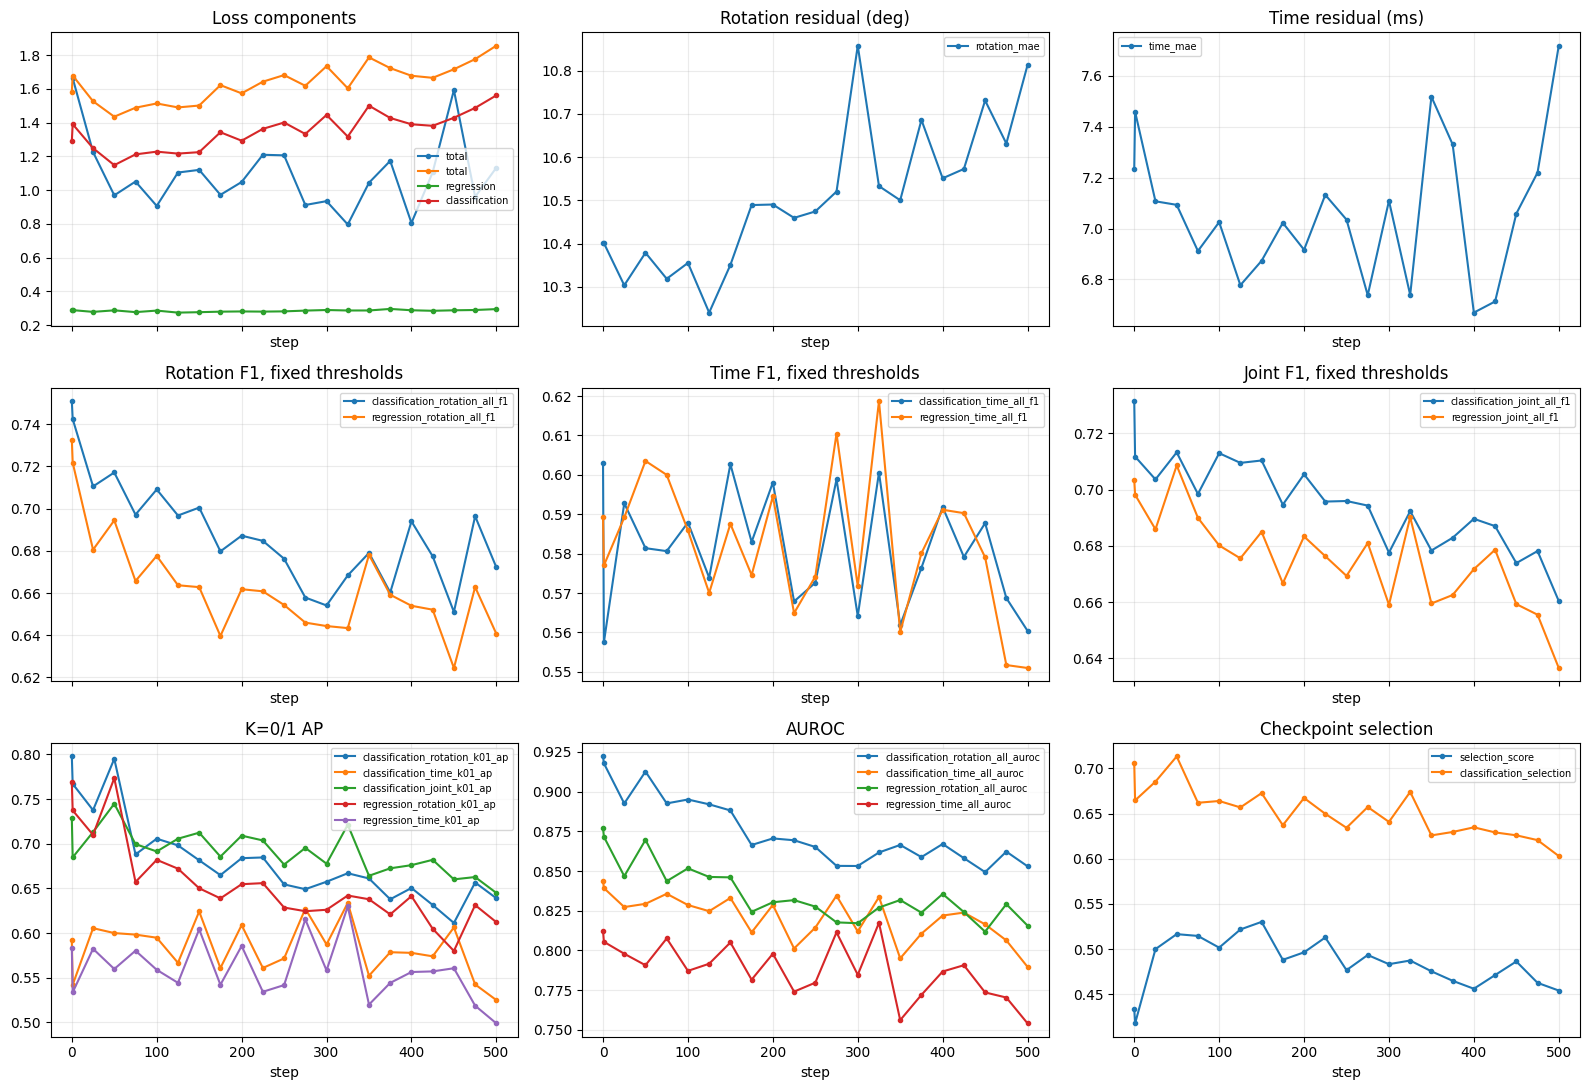

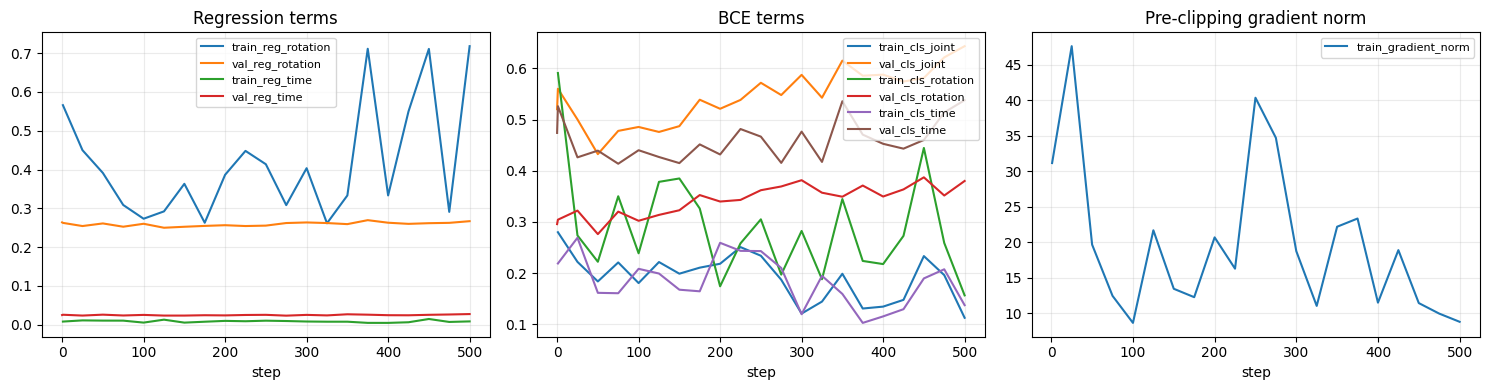

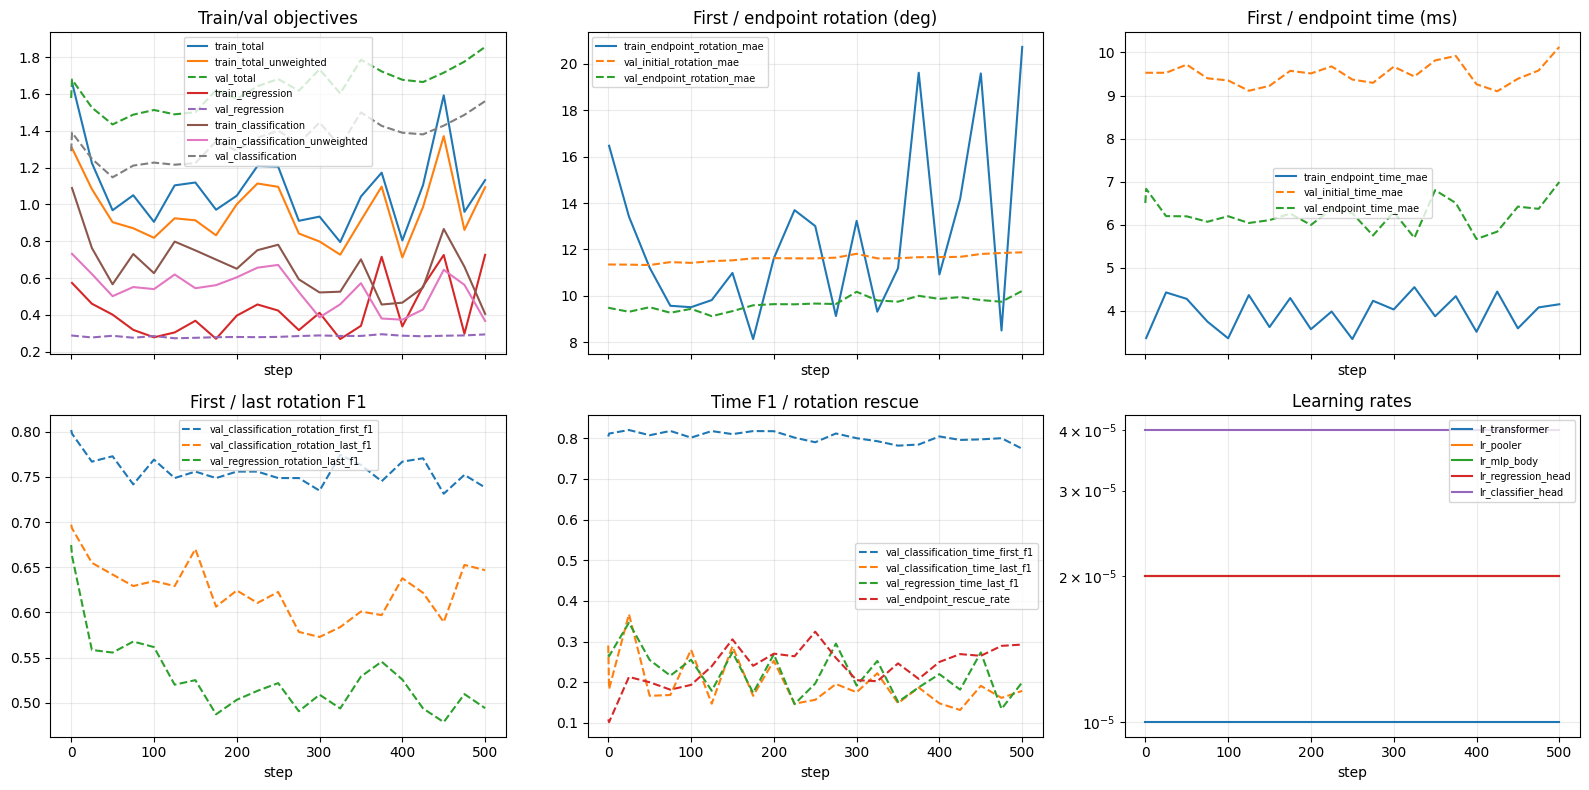

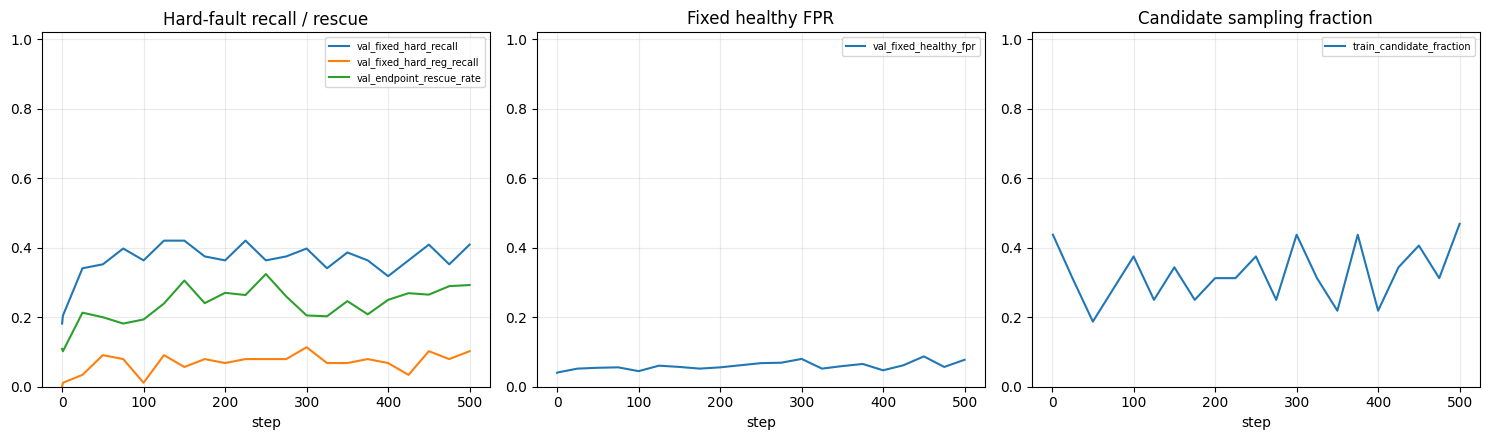

Restored complete pretrained Notebook 78 state.


In [17]:
stochastic_history = []
if RUN_STOCHASTIC_TEST and not RESUME_TRAINING:
    model.load_state_dict(initial_state, strict=True)
    diagnostic_optimizer = make_optimizer(model)
    rng_pool = np.random.default_rng(RANDOM_SEED + 811)
    pool_ids = rng_pool.choice(len(train_bank), min(STOCHASTIC_PHYSICAL_ROLLOUTS, len(train_bank)), replace=False)
    diag_bank = [train_bank[i] for i in pool_ids]
    monitor_seed = VALIDATION_AUG_SEED + 119
    try:
        df, losses = evaluate_training_rollouts(model, val_dataset, stochastic_monitor_bank, split_seed=monitor_seed)
        baseline = rollout_monitor(df, losses)
        metrics = add_fixed_monitor(model, rollout_monitor(df, losses, baseline), val_dataset, stochastic_monitor_bank, split_seed=monitor_seed)
        del df
        stochastic_history.append(history_row('step', 0, {}, metrics) | {f'lr_{g["name"]}':g['lr'] for g in diagnostic_optimizer.param_groups})
        print_rollout_monitor('Initial 78', metrics, diagnostic_optimizer)
        best = metrics['selection_score']
        save_joint_checkpoint(STOCHASTIC_BEST_PATH, model, diagnostic_optimizer, None, 0, metrics)
        for step in range(1, STOCHASTIC_STEPS+1):
            rng = np.random.default_rng(RANDOM_SEED + 777_000 + step)
            chosen = rng.choice(len(diag_bank), min(PHYSICAL_WINDOWS_PER_UPDATE, len(diag_bank)), replace=False)
            entries = [diag_bank[i] for i in chosen]
            windows = build_physical_rollout(train_dataset, entries, TRAIN_AUG_SEED + step * 7)
            cases = sample_fault_cases(len(entries), rng)
            train = train_rollout_batch(model, diagnostic_optimizer, windows, cases)
            del windows, cases
            if step == 1 or step % STOCHASTIC_PRINT_EVERY == 0 or step == STOCHASTIC_STEPS:
                df, losses = evaluate_training_rollouts(model, val_dataset, stochastic_monitor_bank, split_seed=monitor_seed)
                metrics = add_fixed_monitor(model, rollout_monitor(df, losses, baseline), val_dataset, stochastic_monitor_bank, split_seed=monitor_seed)
                del df
                stochastic_history.append(history_row('step', step, train, metrics) | {f'lr_{g["name"]}':g['lr'] for g in diagnostic_optimizer.param_groups})
                print_rollout_monitor(f'Step {step}/{STOCHASTIC_STEPS} train={train["objective"]:.4f} reg={train["regression"]:.4f} cls={train["classification"]:.4f}', metrics, diagnostic_optimizer)
                print_hard_train(train)
                if np.isfinite(metrics['selection_score']) and metrics['selection_score'] > best:
                    best = metrics['selection_score']
                    save_joint_checkpoint(STOCHASTIC_BEST_PATH, model, diagnostic_optimizer, None, step, metrics)
                pd.DataFrame(stochastic_history).to_csv(RUN_DIR/'stochastic_history.csv', index=False)
                clear_cuda()
        save_joint_checkpoint(STOCHASTIC_FINAL_PATH, model, diagnostic_optimizer, None, STOCHASTIC_STEPS, metrics)
    finally:
        model.load_state_dict(initial_state, strict=True)
        model.zero_grad(set_to_none=True)
        del diagnostic_optimizer
        clear_cuda()
    plot_rollout_history(stochastic_history, 'step', 'stochastic')
    print('Restored complete pretrained Notebook 78 state.')
else:
    print('Stochastic training skipped.')

## 12. Detailed one-step evaluation (fixed and validation-tuned thresholds)

In [ ]:
def fit_thresholds(df):
    part = df[df.fault_count.isin((0,1))]
    thresholds = default_thresholds()
    for task in TASKS:
        y = part[f'target_{task}'].to_numpy(bool)
        if not (y.any() and (~y).any()): raise ValueError(f'No positive/negative validation examples for {task}')
        p = part[f'prob_{task}'].to_numpy(float)
        def objective(scores, threshold, inclusive):
            a = scores >= threshold if inclusive else scores > threshold
            m = classification_counts(y,a)
            # Tie-break by specificity, then higher threshold.
            return (np.nan_to_num(m['f1'],nan=-1.), np.nan_to_num(m['specificity'],nan=-1.), threshold)
        thresholds['classification'][task] = float(max(PROBABILITY_THRESHOLDS,key=lambda t:objective(p,t,True)))
        if task != 'joint':
            field, candidates = ('predicted_rotation_deg', REG_ROT_THRESHOLDS_DEG) if task=='rotation' else ('predicted_abs_tau_ms',REG_TIME_THRESHOLDS_MS)
            thresholds['regression'][task] = float(max(candidates,key=lambda t:objective(part[field].to_numpy(float),t,False)))
    return thresholds


def detailed_reports(df, label, thresholds, *, include_classification=True):
    detection_rows, residual_rows = [], []
    groups = [('all','all',df)]
    groups += [('K',str(k),df[df.fault_count==k]) for k in FAULT_COUNTS]
    groups += [('sensor',s,df[df.sensor==s]) for s in CALIBRATION_KEYS]
    groups += [('K_sensor',f'{k}|{s}',df[(df.fault_count==k)&(df.sensor==s)]) for k in FAULT_COUNTS for s in CALIBRATION_KEYS]
    groups += [('mode',mode,df[df.fault_mode==mode]) for mode in ('none',*FAULT_MODES)]
    for group,value,part in groups:
        if part.empty: continue
        residual_rows.append(dict(checkpoint=label, group=group, value=value, n=len(part), **regression_summary(part)))
        for decision,t in (('fixed',default_thresholds()),('validation_tuned',thresholds)):
            for method in (('regression','classification') if include_classification else ('regression',)):
                for task in TASKS:
                    score,alarm = score_and_alarm(part,method,task,t)
                    y = part[f'target_{task}'].to_numpy(bool)
                    m = metrics_for_scores(y,score,alarm)
                    cases = pd.DataFrame({'case_id':part.case_id,'correct':y==alarm}).groupby('case_id').correct.all()
                    detection_rows.append(dict(checkpoint=label,decision=decision,method=method,task=task,group=group,value=value,exact_case_accuracy=cases.mean() if group not in ('sensor','K_sensor') else np.nan,**m))
    return pd.DataFrame(detection_rows),pd.DataFrame(residual_rows)


def assess_checkpoints(paths, calibration_indices, assessment_dataset, assessment_indices, *, calibration_seed, assessment_seed, output_prefix, include_initial_classification=False):
    # Reuse one temporary model; do not mutate the model that is being trained.
    probe = make_initial_model()
    detection, regression, selected = [], [], {}
    for label,path in paths.items():
        load_evaluation_model(probe, label, path)
        calibration_df, _ = evaluate_cases(probe,val_dataset,calibration_indices,split_seed=calibration_seed)
        thresholds = fit_thresholds(calibration_df)
        if label == '002.27': thresholds['classification'] = default_thresholds()['classification']
        selected[label] = thresholds
        if label == '002.27': calibration_df[['prob_joint','prob_rotation','prob_time']] = np.nan
        calibration_df.to_csv(RUN_DIR/f'{output_prefix}_{label}_threshold_calibration.csv',index=False)
        if assessment_dataset is val_dataset and calibration_seed == assessment_seed and np.array_equal(calibration_indices, assessment_indices):
            assessment_df = calibration_df
        else:
            assessment_df, _ = evaluate_cases(probe,assessment_dataset,assessment_indices,split_seed=assessment_seed)
        if label == '002.27': assessment_df[['prob_joint','prob_rotation','prob_time']] = np.nan
        assessment_df.to_csv(RUN_DIR/f'{output_prefix}_{label}_scores.csv',index=False)
        det,reg = detailed_reports(assessment_df,label,thresholds,include_classification=(label != '002.27'))
        detection.append(det); regression.append(reg)
        print(label,'thresholds:',thresholds,'| regression:',regression_summary(assessment_df))
        del calibration_df,assessment_df
    del probe
    clear_cuda()
    det,reg = pd.concat(detection,ignore_index=True),pd.concat(regression,ignore_index=True)
    det.to_csv(RUN_DIR/f'{output_prefix}_detection.csv',index=False)
    reg.to_csv(RUN_DIR/f'{output_prefix}_regression.csv',index=False)
    (RUN_DIR/f'{output_prefix}_thresholds.json').write_text(json.dumps(selected,indent=2))
    display(reg[(reg.group=='all')|((reg.group=='K')&reg.value.isin(['0','1']))].round(3))
    display(det[(det.decision=='validation_tuned')&((det.group=='all')|((det.group=='K')&det.value.isin(['0','1'])))][['checkpoint','method','task','group','value','precision','recall','f1','ap','auroc','false_positive_rate','exact_case_accuracy']].round(3))
    print('Clean per-sensor false alarms (K=0):')
    display(det[(det.decision=='validation_tuned')&(det.group=='K_sensor')&det.value.str.startswith('0|')][['checkpoint','method','task','value','false_positive_rate','fp','tn']].round(3))
    return det,reg,selected

## 13. Matched rollout checkpoint assessment
Counts are pooled from individual sensor predictions. All models receive identical initial faults and windows, but their current GT labels may differ after their own updates. Fixed 0.5 / 3° / 10 ms thresholds isolate changes in the models. Optional threshold calibration is in the one-step reports.

In [ ]:
def assess_fixed_hard_checkpoints(paths, dataset, bank, *, split_seed, prefix):
    names = tuple(dict.fromkeys(name for name, _ in bank))
    selected = spread_bank(bank, names, HARD_ASSESS_ROLLOUTS_PER_SEQUENCE, split_seed + 932)
    probe = make_initial_model()
    tables, rows = [], []
    reference_columns = ['sequence','start_index','physical_index','initial_rotation_deg','initial_tau_ms','true_rotation_deg','true_tau_ms','reference_rotation_deg','reference_tau_ms']
    reference_table = None
    try:
        for label, path in paths.items():
            load_evaluation_model(probe, label, path)
            df = fixed_reference_scores(probe, dataset, selected, split_seed=split_seed + 700_003)
            key = ['rollout_id','step','sensor']
            matched = df.set_index(key).sort_index()[reference_columns]
            if reference_table is None: reference_table = matched.copy()
            else: pd.testing.assert_frame_equal(reference_table, matched, check_exact=False, atol=1e-5, rtol=1e-6)
            df['checkpoint'] = label
            hard = (df.true_rotation_deg > HARD_MIN_ROTATION_DEG) & (df.reference_rotation_deg <= GT_ROT_TOL_DEG)
            df['reference_hard_rotation'] = hard
            for step, part in [('all_after_first', df[df.step>0] if TRAIN_ROLLOUT_WINDOWS > 1 else df)] + list(df.groupby('step')):
                healthy = part.true_rotation_deg <= GT_ROT_TOL_DEG
                for name, g in [('all_hard', part[part.reference_hard_rotation]), ('healthy', part[healthy])] + [(f'({lo:g},{hi:g}]', part[part.reference_hard_rotation & (part.true_rotation_deg>lo) & (part.true_rotation_deg<=hi)]) for lo,hi in ((3,10),(10,45),(45,90),(90,180.001))]:
                    for method in ('regression','classification') if label != '002.27' else ('regression',):
                        _, alarm = score_and_alarm(g,method,'rotation',default_thresholds())
                        rows.append(dict(checkpoint=label, step=step, subset=name, method=method, n=len(g), n_alarms=int(alarm.sum()), alarm_rate=float(alarm.mean()) if len(g) else np.nan))
            if label == '002.27': df[['prob_joint','prob_rotation','prob_time']] = np.nan
            tables.append(df)
    finally:
        del probe
        clear_cuda()
    raw, metrics = pd.concat(tables,ignore_index=True), pd.DataFrame(rows)
    raw.to_csv(RUN_DIR/f'{prefix}_fixed_reference_scores.csv', index=False)
    metrics.to_csv(RUN_DIR/f'{prefix}_fixed_reference_metrics.csv', index=False)
    display(metrics[metrics.step=='all_after_first'].round(3))
    fig, axes = plt.subplots(1,2,figsize=(13,4.5),sharey=True)
    for ax, subset, title in zip(axes, ('all_hard','healthy'), ('Fixed 78 hard positives: recall','Fixed 78 healthy: false-positive rate')):
        part = metrics[(metrics.subset==subset) & (metrics.step!='all_after_first')]
        for (label,method),g in part.groupby(['checkpoint','method']):
            g=g.sort_values('step'); ax.plot(g.step.astype(int),g.alarm_rate,'-o',label=f'{label} {method}')
        ax.set(title=title,xlabel='Window index',ylim=(0,1.02)); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'{prefix}_fixed_reference.png')
    return raw, metrics


def assess_rollout_checkpoints(paths, dataset, bank, *, split_seed, prefix):
    probe = make_initial_model()
    tables, metric_rows, reg_rows = [], [], []
    try:
        for label, path in paths.items():
            load_evaluation_model(probe, label, path)
            df, losses = evaluate_training_rollouts(probe, dataset, bank, split_seed=split_seed)
            df['checkpoint'] = label
            tables.append(df)
            for step, part in df.groupby('step'):
                for group, value, g in [('all','all',part)] + [('initial_K',str(k),part[part.fault_count==k]) for k in FAULT_COUNTS] + [('sensor',s,part[part.sensor==s]) for s in CALIBRATION_KEYS]:
                    if g.empty: continue
                    reg_rows.append(dict(checkpoint=label, step=step, group=group, value=value, n=len(g), ctg_rotation=float(g.true_rotation_deg.mean()), ctg_time=float(g.true_tau_ms.abs().mean()), **regression_summary(g)))
                    for task in TASKS:
                        y = g[f'target_{task}'].to_numpy(bool)
                        _, reg_alarm = score_and_alarm(g,'regression',task,default_thresholds())
                        for method in ('regression', 'classification') if label != '002.27' else ('regression',):
                            score, alarm = score_and_alarm(g,method,task,default_thresholds())
                            missed = y & ~reg_alarm
                            metric_rows.append(dict(checkpoint=label,step=step,group=group,value=value,task=task,method=method,regression_missed=int(missed.sum()),rescued=int((missed & alarm).sum()),**metrics_for_scores(y,score,alarm)))
            print(label, '| rollout objective', round(losses['objective'],4) if label != '002.27' else 'not applicable (no trained classifier)', '| endpoint', regression_summary(df[df.step==TRAIN_ROLLOUT_WINDOWS-1]), flush=True)
    finally:
        del probe
        clear_cuda()
    raw, metrics, reg = pd.concat(tables,ignore_index=True), pd.DataFrame(metric_rows), pd.DataFrame(reg_rows)
    keys = ['rollout_id','step','sensor']
    ref = tables[0].set_index(keys).sort_index()
    for table in tables[1:]:
        other = table.set_index(keys).sort_index()
        assert ref.index.equals(other.index)
        pd.testing.assert_frame_equal(ref[['sequence','start_index','physical_index','initial_rotation_deg','initial_tau_ms']], other[['sequence','start_index','physical_index','initial_rotation_deg','initial_tau_ms']])
    raw.loc[raw.checkpoint=='002.27', ['prob_joint','prob_rotation','prob_time']] = np.nan
    raw.to_csv(RUN_DIR/f'{prefix}_rollout_scores.csv',index=False)
    metrics.to_csv(RUN_DIR/f'{prefix}_rollout_detection.csv',index=False)
    reg.to_csv(RUN_DIR/f'{prefix}_rollout_regression.csv',index=False)
    display(reg[(reg.group=='all') & reg.step.isin([0,TRAIN_ROLLOUT_WINDOWS-1])].round(3))
    display(metrics[(metrics.group=='all') & metrics.step.isin([0,TRAIN_ROLLOUT_WINDOWS-1])][['checkpoint','step','method','task','n','tp','fp','fn','tn','f1','ap','recall','accuracy','regression_missed','rescued']].round(3))
    fig, axes = plt.subplots(2,3,figsize=(16,8),sharex=True)
    for label,g in reg[reg.group=='all'].groupby('checkpoint'):
        axes[0,0].plot(g.step,g.rotation_mae,'-o',label=label)
        axes[1,0].plot(g.step,g.time_mae,'-o',label=label)
    for (label,method,task),g in metrics[(metrics.group=='all') & metrics.task.isin(['rotation','time'])].groupby(['checkpoint','method','task']):
        row = 0 if task=='rotation' else 1
        axes[row,1].plot(g.step,g.f1,'-o',label=f'{label} {method}')
        axes[row,2].plot(g.step,g.recall,'-o',label=f'{label} {method}')
    for ax,title in zip(axes.flat, ('Post-update rotation MAE','Rotation F1','Rotation recall','Post-update time MAE','Time F1','Time recall')):
        ax.set(title=title,xlabel='Window index'); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig, f'{prefix}_rollout_metrics.png')
    return raw, metrics, reg

stochastic_paths = {'002.27':None,'78_best':None,'stochastic_best':STOCHASTIC_BEST_PATH,'stochastic_final':STOCHASTIC_FINAL_PATH}
if RUN_STOCHASTIC_CHECKPOINT_EVALUATION and not RESUME_TRAINING:
    stochastic_detection,stochastic_regression,stochastic_thresholds = assess_checkpoints(stochastic_paths,stochastic_monitor_indices,val_dataset,stochastic_assessment_indices,calibration_seed=VALIDATION_AUG_SEED+119,assessment_seed=VALIDATION_AUG_SEED+431,output_prefix='stochastic_assessment',include_initial_classification=True)
if RUN_STOCHASTIC_ROLLOUT_ASSESSMENT and not RESUME_TRAINING:
    stochastic_rollout_df, stochastic_rollout_metrics, stochastic_rollout_reg = assess_rollout_checkpoints(stochastic_paths,val_dataset,stochastic_assessment_bank,split_seed=VALIDATION_AUG_SEED+431,prefix='stochastic_assessment')
if RUN_STOCHASTIC_ROLLOUT_ASSESSMENT and not RESUME_TRAINING:
    stochastic_fixed_df, stochastic_fixed_metrics = assess_fixed_hard_checkpoints(stochastic_paths,val_dataset,stochastic_assessment_bank,split_seed=VALIDATION_AUG_SEED+431,prefix='stochastic_assessment')


## 14. Full fine-tuning (fresh optimizer, independent of stochastic run)
Checkpoint selection uses rollout AP and retention penalties on first-step and endpoint residuals, all relative to the source 78. The plateau scheduler monitors the validation rollout objective. Epoch 0 is eligible as a checkpoint, so training is never forced to replace a better source model.

In [ ]:
training_history = []
if RUN_FULL_TRAINING:
    model.load_state_dict(initial_state,strict=True)
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=LR_REDUCTION_FACTOR,patience=LR_PATIENCE_EPOCHS)
    monitor_seed = VALIDATION_AUG_SEED
    reference_df,reference_losses = evaluate_training_rollouts(model,val_dataset,full_monitor_bank,split_seed=monitor_seed)
    full_baseline = rollout_monitor(reference_df,reference_losses)
    initial_metrics = add_fixed_monitor(model, rollout_monitor(reference_df,reference_losses,full_baseline), val_dataset, full_monitor_bank, split_seed=monitor_seed)
    print_rollout_monitor('Pretrained 78 initial',initial_metrics,optimizer)
    del reference_df
    start_epoch,global_step = 0,0
    best_scores = {'selection_score':-np.inf,'classification_selection':-np.inf,'regression_selection':-np.inf,'hard_selection':-np.inf}
    if RESUME_TRAINING:
        state = load_joint_checkpoint(LAST_CHECKPOINT_PATH,model)
        optimizer.load_state_dict(state['optimizer_state_dict'])
        scheduler.load_state_dict(state['scheduler_state_dict'])
        start_epoch,global_step = int(state['step']),int(state['global_step'])
        best_scores = state['best_scores']
        train_shuffle_generator.set_state(state['train_shuffle_state'])
        torch.set_rng_state(state['torch_rng_state'])
        if DEVICE.type=='cuda' and state['cuda_rng_state']: torch.cuda.set_rng_state_all(state['cuda_rng_state'])
        history_path = RUN_DIR/'training_history.csv'
        if history_path.is_file(): training_history = pd.read_csv(history_path).query('epoch <= @start_epoch').to_dict('records')
        del state
    else:
        if any(path.exists() for path in (BEST_CHECKPOINT_PATH,BEST_CLASSIFICATION_PATH,BEST_REGRESSION_PATH,BEST_HARD_PATH,LAST_CHECKPOINT_PATH)):
            raise FileExistsError('Full-training checkpoints already exist. Change RUN_NAME or resume.')
        training_history.append(history_row('epoch',0,{},initial_metrics) | {f'lr_{g["name"]}':g['lr'] for g in optimizer.param_groups})
        best_scores = {k:float(initial_metrics[k]) if np.isfinite(initial_metrics[k]) else -np.inf for k in best_scores}
        for path in (BEST_CHECKPOINT_PATH,BEST_CLASSIFICATION_PATH,BEST_REGRESSION_PATH,BEST_HARD_PATH,LAST_CHECKPOINT_PATH):
            save_joint_checkpoint(path,model,optimizer,scheduler,0,initial_metrics,best_scores,0)
        pd.DataFrame(training_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        # Ensure independent, deterministic full-training shuffle/initial random streams.
        train_shuffle_generator.manual_seed(RANDOM_SEED+25)
        torch.manual_seed(RANDOM_SEED+89)
        if DEVICE.type=='cuda': torch.cuda.manual_seed_all(RANDOM_SEED+89)
    for epoch in range(start_epoch,NUM_EPOCHS):
        print(f'\nEpoch {epoch+1}/{NUM_EPOCHS} | LR {lr_string(optimizer)}', flush=True)
        train,global_step = run_train_epoch(model,optimizer,epoch,global_step)
        monitor_df,losses = evaluate_training_rollouts(model,val_dataset,full_monitor_bank,split_seed=monitor_seed)
        val = add_fixed_monitor(model, rollout_monitor(monitor_df,losses,full_baseline), val_dataset, full_monitor_bank, split_seed=monitor_seed)
        del monitor_df
        scheduler.step(val['objective'])
        row = history_row('epoch',epoch+1,train,val)
        row.update(global_step=global_step,**{f'lr_{g["name"]}':g['lr'] for g in optimizer.param_groups})
        training_history.append(row)
        print_rollout_monitor(f'Epoch {epoch+1} train={train["objective"]:.4f} reg={train["regression"]:.4f} cls={train["classification"]:.4f}',val,optimizer)
        print_hard_train(train)
        # print('Train K fractions:',[round(train[f'k{k}_fraction'],3) for k in range(4)],'| regression relative MAE:',round(val['rotation_ratio'],3),round(val['time_ratio'],3))
        checkpoints = {'selection_score':BEST_CHECKPOINT_PATH,'classification_selection':BEST_CLASSIFICATION_PATH,'regression_selection':BEST_REGRESSION_PATH,'hard_selection':BEST_HARD_PATH}
        improved = [k for k in checkpoints if np.isfinite(val[k]) and val[k]>best_scores[k]]
        for k in improved: best_scores[k]=float(val[k])
        for k in improved:
            save_joint_checkpoint(checkpoints[k],model,optimizer,scheduler,epoch+1,val,best_scores,global_step)
            print('Saved',checkpoints[k].name)
        save_joint_checkpoint(LAST_CHECKPOINT_PATH,model,optimizer,scheduler,epoch+1,val,best_scores,global_step)
        pd.DataFrame(training_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        clear_cuda()
    plot_rollout_history(training_history,'epoch','full_training')
else:
    print('Full training disabled; existing checkpoints may still be evaluated.')

## 15. Full checkpoint assessments: one-step and chronological rollouts

In [ ]:
full_paths = {'002.27':None,'78_best':None,'best':BEST_CHECKPOINT_PATH,'best_classification':BEST_CLASSIFICATION_PATH,'best_regression':BEST_REGRESSION_PATH,'best_hard':BEST_HARD_PATH,'last':LAST_CHECKPOINT_PATH}
if RUN_DETAILED_EVALUATION or RUN_TEST_EVALUATION:
    for name,path in full_paths.items():
        if path is not None and not path.is_file(): raise FileNotFoundError(f'Missing {name}: {path}')
if RUN_DETAILED_EVALUATION:
    full_validation_detection,full_validation_regression,validation_thresholds = assess_checkpoints(full_paths,detailed_val_indices,val_dataset,detailed_val_indices,calibration_seed=VALIDATION_AUG_SEED+331,assessment_seed=VALIDATION_AUG_SEED+331,output_prefix='full_validation')
if RUN_TEST_EVALUATION:
    full_test_detection,full_test_regression,test_thresholds = assess_checkpoints(full_paths,detailed_val_indices,test_dataset,detailed_test_indices,calibration_seed=VALIDATION_AUG_SEED+331,assessment_seed=TEST_AUG_SEED+331,output_prefix='full_test')

In [ ]:
if RUN_DETAILED_EVALUATION:
    full_rollout_df, full_rollout_metrics, full_rollout_regression = assess_rollout_checkpoints(full_paths,val_dataset,full_assessment_bank,split_seed=VALIDATION_AUG_SEED+331,prefix='full_validation')
if RUN_TEST_EVALUATION:
    full_test_rollout_df, full_test_rollout_metrics, full_test_rollout_regression = assess_rollout_checkpoints(full_paths,test_dataset,full_test_bank,split_seed=TEST_AUG_SEED+331,prefix='full_test')
if RUN_DETAILED_EVALUATION:
    full_fixed_df, full_fixed_metrics = assess_fixed_hard_checkpoints(full_paths,val_dataset,full_assessment_bank,split_seed=VALIDATION_AUG_SEED+331,prefix='full_validation')
if RUN_TEST_EVALUATION:
    full_test_fixed_df, full_test_fixed_metrics = assess_fixed_hard_checkpoints(full_paths,test_dataset,full_test_bank,split_seed=TEST_AUG_SEED+331,prefix='full_test')


## 16. Reload saved learning curves after training or interruption

In [ ]:
history_file = RUN_DIR/'training_history.csv'
if history_file.is_file():
    hist = pd.read_csv(history_file).sort_values('epoch')
    plot_rollout_history(hist.to_dict('records'), 'epoch', 'full_training')
    display(hist.tail(5).round(5))
else:
    print('No full-training history yet.')

## 17. Controlled K=1 one-step angle sweep

In [ ]:
def sweep_metrics(df,label,thresholds,include_classifier):
    rows=[]
    for sensor in ('all',*CALIBRATION_KEYS):
        data=df if sensor=='all' else df[df.selected_sensor==sensor]
        for angle,part in data.groupby('angle_deg'):
            selected=part[part.sensor==part.selected_sensor]
            healthy=part[part.sensor!=part.selected_sensor]
            y=part.target_rotation.to_numpy(bool)
            if not len(selected): continue
            for method in (('regression','classification') if include_classifier else ('regression',)):
                for decision in ('fixed_regression','validation_tuned'):
                    t=default_thresholds() if decision=='fixed_regression' and method=='regression' else thresholds
                    score,alarm=score_and_alarm(part,method,'rotation',t)
                    m=metrics_for_scores(y,score,alarm)
                    exact=pd.DataFrame(dict(case=part.case_id,correct=y==alarm)).groupby('case').correct.all().mean()
                    rows.append(dict(checkpoint=label,method=method,decision=decision,sensor=sensor,angle_deg=angle,n_cases=part.case_id.nunique(),f1=m['f1'] if y.any() else np.nan,recall=m['recall'],precision=m['precision'],exact=exact,selected_residual_median=selected.residual_deg.median(),selected_residual_p90=selected.residual_deg.quantile(.9),healthy_correction_p90=healthy.predicted_rotation_deg.quantile(.9)))
    return pd.DataFrame(rows)


if RUN_CONTROLLED_SWEEP:
    if not BEST_CHECKPOINT_PATH.is_file(): raise FileNotFoundError(BEST_CHECKPOINT_PATH)
    sweep_dataset,sweep_names,sweep_split=(test_dataset,TEST_NAMES,'test') if RUN_TEST_EVALUATION else (val_dataset,VAL_NAMES,'validation')
    sweep_indices=select_spread_indices_by_names(sweep_dataset,sweep_names,SWEEP_WINDOWS_PER_SEQUENCE,RANDOM_SEED+900)
    sweep_seed=(TEST_AUG_SEED if RUN_TEST_EVALUATION else VALIDATION_AUG_SEED)+900
    thresholds_path=RUN_DIR/('full_test_thresholds.json' if RUN_TEST_EVALUATION else 'full_validation_thresholds.json')
    if not thresholds_path.is_file(): raise FileNotFoundError('Run detailed validation/test evaluation before sweep to obtain validation-selected thresholds.')
    thresholds=json.loads(thresholds_path.read_text())
    probe=make_initial_model()
    sweep_reports=[]
    for label,path in {'002.27':None,'78_best':None,'best':BEST_CHECKPOINT_PATH}.items():
        load_evaluation_model(probe,label,path)
        df,_=evaluate_cases(probe,sweep_dataset,sweep_indices,split_seed=sweep_seed,controlled=True)
        if label == '002.27': df[['prob_joint','prob_rotation','prob_time']] = np.nan
        df.to_csv(RUN_DIR/f'{sweep_split}_controlled_{label}_scores.csv',index=False)
        sweep_reports.append(sweep_metrics(df,label,thresholds[label],label != '002.27'))
        del df
    del probe
    clear_cuda()
    sweep_df=pd.concat(sweep_reports,ignore_index=True)
    sweep_df.to_csv(RUN_DIR/f'{sweep_split}_controlled_summary.csv',index=False)
    for decision in ('fixed_regression','validation_tuned'):
        fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
        for ax,sensor in zip(axes.flat,('all',*CALIBRATION_KEYS)):
            part=sweep_df[(sweep_df.sensor==sensor)&(sweep_df.decision==decision)]
            for (checkpoint,method),g in part.groupby(['checkpoint','method']):
                ax.plot(g.angle_deg,g.f1,'-o',label=f'{checkpoint} {method}')
            ax.axhline(.5,color='gray',linestyle=':'); ax.set(title=f'Injected sensor: {sensor}',xlabel='Injected angle (deg)',ylabel='Positive-class micro-F1',ylim=(0,1.03)); ax.grid(alpha=.25); ax.legend(fontsize=8)
        fig.suptitle(f'{sweep_split} | matched K=1 rotation-only | GT > {GT_ROT_TOL_DEG:g}° | {decision}')
        finish_figure(fig,f'{sweep_split}_k1_f1_{decision}.png')
    fig,axes=plt.subplots(3,2,figsize=(12,11),sharex=True)
    for row,sensor in enumerate(CALIBRATION_KEYS):
        part=sweep_df[(sweep_df.sensor==sensor)&(sweep_df.method=='regression')&(sweep_df.decision=='fixed_regression')]
        for checkpoint,g in part.groupby('checkpoint'):
            x=g.angle_deg.to_numpy(float); median=g.selected_residual_median.to_numpy(float); p90=g.selected_residual_p90.to_numpy(float)
            axes[row,0].plot(x,median,'-o',label=checkpoint); axes[row,0].fill_between(x,median,p90,alpha=.15)
            axes[row,1].plot(x,g.healthy_correction_p90,'-o',label=checkpoint)
        axes[row,0].plot([0,179],[0,179],':',color='gray',label='No update')
        axes[row,1].axhline(GT_ROT_TOL_DEG,color='gray',linestyle=':')
        axes[row,0].set(title=f'{sensor}: residual median and p90',ylabel='Degrees')
        axes[row,1].set(title=f'{sensor}: healthy-head correction p90',ylabel='Degrees')
        for ax in axes[row]: ax.set_xlabel('Injected angle (deg)'); ax.grid(alpha=.25); ax.legend(fontsize=8)
    finish_figure(fig,f'{sweep_split}_k1_regression_retention.png')

## 18. Long chronological rollout stress test (12 windows by default)
Compare 002.27, 78 best and 79 best on the original controlled angle/time cases, with actual evolving ground-truth error labels. This horizon is independent of the training horizon.

In [ ]:
def rollout_cases(rng):
    cases=[]
    for key in CALIBRATION_KEYS:
        axis=rng.normal(size=3); axis/=np.linalg.norm(axis)
        for angle in ROLLOUT_ANGLES_DEG:
            if angle==0 and key!=CALIBRATION_KEYS[0]: continue
            cases.append(dict(source_row=0,rotations={k:float(angle) if k==key else 0. for k in CALIBRATION_KEYS},tau_ms={k:0. for k in CALIBRATION_KEYS},axes={k:axis if k==key else np.zeros(3) for k in CALIBRATION_KEYS},initial_sensor=key if angle else 'none',initial_angle_deg=float(angle),initial_tau_ms=0.))
        for tau in ROLLOUT_TIME_FAULT_MS:
            for sign in (-1,1):
                cases.append(dict(source_row=0,rotations={k:0. for k in CALIBRATION_KEYS},tau_ms={k:sign*float(tau) if k==key else 0. for k in CALIBRATION_KEYS},axes={k:np.zeros(3) for k in CALIBRATION_KEYS},initial_sensor=key,initial_angle_deg=0.,initial_tau_ms=sign*float(tau)))
    return cases


@torch.inference_mode()
def evaluate_rollouts(net,dataset,names,label,thresholds,include_classifier):
    net.eval(); rows=[]; rollout_id=0
    for seq_i,sequence in enumerate(names):
        available=np.asarray(dataset.window_indices_for_sequence(sequence),dtype=int)
        max_start=len(available)-ROLLOUT_NUM_WINDOWS
        if max_start<0: continue
        starts=np.unique(np.linspace(0,max_start,min(ROLLOUT_STARTS_PER_SEQUENCE,max_start+1)).round().astype(int))
        for start in starts:
            indices=available[start:start+ROLLOUT_NUM_WINDOWS]
            seed=TEST_AUG_SEED+500_000+seq_i*100_003+int(start)*1009
            windows=[]
            for idx in indices:
                raw=window_batch_to(collate_windows([dataset[int(idx)]]),DEVICE,dtype=MODEL_DTYPE)
                windows.append(fixed_seeded_physical(raw,seed))
            truth=windows[0].current_calibration
            for w in windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(w.current_calibration[key].transform,truth[key].transform,atol=3e-5,rtol=3e-5)
                    torch.testing.assert_close(w.current_calibration[key].time_offset,truth[key].time_offset,atol=3e-6,rtol=3e-6)
            cases=rollout_cases(np.random.default_rng(seed+51))
            for offset in range(0,len(cases),BATCH_SIZE):
                subset=cases[offset:offset+BATCH_SIZE]; n=len(subset)
                # faulted_window_from_cases copies measurements and sets prior; on later steps
                # replace that prior with the previous model update, never reinject the fault.
                states=faulted_window_from_cases(windows[0],subset).current_calibration
                for step,w in enumerate(windows):
                    repeated=faulted_window_from_cases(w,subset)
                    window=WindowBatch(streams=dict(repeated.streams),current_calibration=states,metadata=dict(repeated.metadata),targets=None,dataset_indices=None)
                    out=net(tokenize_window(window)); prob=out.logits.sigmoid()
                    if out.calibration_keys!=CALIBRATION_KEYS: raise AssertionError('Unexpected rollout key order')
                    updated={}
                    for j,key in enumerate(CALIBRATION_KEYS):
                        state=states[key]; pred=out.predictions[key]; R=state.transform[:,:3,:3]; gt_R=truth[key].transform[:,:3,:3].expand_as(R)
                        theta=distance_so3_deg(R,gt_R)
                        tau=1000.*(state.time_offset.reshape(-1)-truth[key].time_offset.reshape(-1)[0])
                        dR=pred.delta_rotation; dt=pred.delta_tau.reshape_as(state.time_offset)
                        magnitude=distance_so3_deg(dR,torch.eye(3,device=DEVICE,dtype=MODEL_DTYPE).expand_as(dR))
                        new_T=state.transform.clone(); new_T[:,:3,:3]=dR@R
                        updated[key]=CalibrationState(transform=new_T,time_offset=state.time_offset+dt if ROLLOUT_UPDATE_TIME else state.time_offset)
                        residual=distance_so3_deg(new_T[:,:3,:3],gt_R)
                        for b,c in enumerate(subset):
                            rows.append(dict(checkpoint=label,sequence=sequence,start_index=int(indices[0]),rollout_id=rollout_id+b,step=step,sensor=key,initial_sensor=c['initial_sensor'],initial_angle_deg=c['initial_angle_deg'],initial_tau_ms=c['initial_tau_ms'],true_rotation_deg=float(theta[b]),true_tau_ms=float(tau[b]),predicted_rotation_deg=float(magnitude[b]),predicted_abs_tau_ms=float(dt.reshape(-1)[b].abs()*1000),residual_deg=float(residual[b]),tau_residual_ms=float(tau[b]+dt.reshape(-1)[b]*1000),target_rotation=int(theta[b]>GT_ROT_TOL_DEG),target_time=int(tau[b].abs()>GT_TAU_TOL_MS),target_joint=int((theta[b]>GT_ROT_TOL_DEG)|(tau[b].abs()>GT_TAU_TOL_MS)),prob_joint=float(prob[b,j,0]),prob_rotation=float(prob[b,j,1]),prob_time=float(prob[b,j,2])))
                    states=updated
                rollout_id+=n
            del windows
    if not rows: raise RuntimeError('No chronological rollout cases')
    df=pd.DataFrame(rows)
    for method in (('regression','classification') if include_classifier else ('regression',)):
        for task in TASKS:
            _,alarm=score_and_alarm(df,method,task,thresholds)
            df[f'alarm_{method}_{task}']=alarm
    return df


if RUN_ROLLOUT_EVALUATION:
    rollout_dataset,rollout_names,rollout_split=(test_dataset,TEST_NAMES,'test') if RUN_TEST_EVALUATION else (val_dataset,VAL_NAMES,'validation')
    threshold_path=RUN_DIR/('full_test_thresholds.json' if RUN_TEST_EVALUATION else 'full_validation_thresholds.json')
    thresholds=json.loads(threshold_path.read_text())
    probe=make_initial_model(); rollout_tables=[]; rollout_metric_rows=[]
    for label,path in {'002.27':None,'78_best':None,'best':BEST_CHECKPOINT_PATH}.items():
        load_evaluation_model(probe,label,path)
        df=evaluate_rollouts(probe,rollout_dataset,rollout_names,label,thresholds[label],label != '002.27')
        if label == '002.27': df[['prob_joint','prob_rotation','prob_time']] = np.nan
        rollout_tables.append(df)
        for step,g in df.groupby('step'):
            for method in (('regression','classification') if label != '002.27' else ('regression',)):
                for task in TASKS:
                    y=g[f'target_{task}'].to_numpy(bool); score,alarm=score_and_alarm(g,method,task,thresholds[label])
                    rollout_metric_rows.append(dict(checkpoint=label,step=step,method=method,task=task,**metrics_for_scores(y,score,alarm)))
        clear_cuda()
    del probe
    rollout_df=pd.concat(rollout_tables,ignore_index=True); rollout_metrics=pd.DataFrame(rollout_metric_rows)
    rollout_df.to_csv(RUN_DIR/f'{rollout_split}_rollout_scores.csv',index=False)
    rollout_metrics.to_csv(RUN_DIR/f'{rollout_split}_rollout_detection.csv',index=False)
    display(rollout_metrics.round(3))
    # Directly answer the deployment question: does the classifier recover faults
    # missed by correction magnitude, and does it still alarm on stalled updates?
    hybrid_rows = rollout_df[rollout_df.checkpoint=='best'].copy()
    rescue_rows = []
    for step,g in hybrid_rows.groupby('step'):
        for task in TASKS:
            y=g[f'target_{task}'].to_numpy(bool)
            reg_alarm=g[f'alarm_regression_{task}'].to_numpy(bool)
            cls_alarm=g[f'alarm_classification_{task}'].to_numpy(bool)
            still_wrong = (g.residual_deg > GT_ROT_TOL_DEG).to_numpy() if task=='rotation' else (g.tau_residual_ms.abs() > GT_TAU_TOL_MS).to_numpy()
            if task=='joint': still_wrong=((g.residual_deg > GT_ROT_TOL_DEG)|(g.tau_residual_ms.abs() > GT_TAU_TOL_MS)).to_numpy()
            missed=y & ~reg_alarm
            unresolved=y & still_wrong
            def fraction(mask, flag): return float(flag[mask].mean()) if mask.any() else np.nan
            rescue_rows.append(dict(step=step,task=task,currently_faulty=int(y.sum()),regression_missed=int(missed.sum()),classifier_rescued=int((missed & cls_alarm).sum()),rescue_rate=fraction(missed,cls_alarm),unresolved_after_update=int(unresolved.sum()),classifier_recall_on_unresolved=fraction(unresolved,cls_alarm),correction_alarm_recall_on_unresolved=fraction(unresolved,reg_alarm),classifier_fpr_on_currently_healthy=fraction(~y,cls_alarm)))
    rollout_rescue=pd.DataFrame(rescue_rows)
    rollout_rescue.to_csv(RUN_DIR/f'{rollout_split}_rollout_classifier_rescue.csv',index=False)
    display(rollout_rescue.round(3))
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),sharey=True)
    for ax,task in zip(axes,TASKS):
        g=rollout_rescue[rollout_rescue.task==task]
        for field,label in (('rescue_rate','Classifier recall on regressor misses'),('classifier_recall_on_unresolved','Classifier recall on unresolved'),('correction_alarm_recall_on_unresolved','Correction alarm recall on unresolved'),('classifier_fpr_on_currently_healthy','Classifier FPR on healthy')):
            ax.plot(g.step,g[field],'-o',label=label)
        ax.set(title=task,xlabel='Window / update step',ylim=(0,1.03)); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'{rollout_split}_rollout_classifier_rescue.png')
    fig,axes=plt.subplots(2,3,figsize=(15,8))
    for j,task in enumerate(TASKS):
        for (label,method),g in rollout_metrics[rollout_metrics.task==task].groupby(['checkpoint','method']):
            axes[0,j].plot(g.step,g.recall,'-o',label=f'{label} {method}'); axes[1,j].plot(g.step,g.false_positive_rate,'-o',label=f'{label} {method}')
        axes[0,j].set(title=f'{task}: recall on STILL faulty priors',ylabel='Recall',ylim=(0,1.03)); axes[1,j].set(title=f'{task}: alarms on currently healthy priors',ylabel='FPR',ylim=(0,1.03))
        for ax in axes[:,j]: ax.set_xlabel('Window / update step'); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'{rollout_split}_rollout_fault_detection.png')
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    selected=rollout_df[rollout_df.sensor==rollout_df.initial_sensor]
    for (label,angle),g in selected[selected.initial_angle_deg>0].groupby(['checkpoint','initial_angle_deg']):
        curve=g.groupby('step').true_rotation_deg.median(); axes[0].plot(curve.index,curve,'-o',label=f'{label} {angle:g}°')
    for (label,tau),g in selected[selected.initial_tau_ms!=0].assign(initial_abs_tau=lambda d:d.initial_tau_ms.abs()).groupby(['checkpoint','initial_abs_tau']):
        curve=g.assign(abs_tau=g.true_tau_ms.abs()).groupby('step').abs_tau.median(); axes[1].plot(curve.index,curve,'-o',label=f'{label} {tau:g}ms')
    for ax,title,ylabel in zip(axes,('Rotation faults','Time faults'),('Current error (deg)','Current error (ms)')):
        ax.set(title=title,xlabel='Window / update step',ylabel=ylabel); ax.grid(alpha=.25); ax.legend(fontsize=7,ncol=2)
    finish_figure(fig,f'{rollout_split}_rollout_residuals.png')
    clear_cuda()

## 19. Per-angle remaining error and fault awareness, identical initial conditions
After long-rollout evaluation, select an individual start or aggregate all starts. Left: pre-update CTG; right: raw classifier probabilities and baseline binary correction alarm. In aggregate view all alarms and GT fractions are computed on individual predictions; no thresholding of averaged scores.

In [ ]:
VIEW_SENSOR = 'lidar'
VIEW_EXAMPLE = 0  # set None for aggregate
VIEW_CLASSIFIER_THRESHOLD = .5
if 'rollout_df' in globals():
    starts = rollout_df[['sequence','start_index']].drop_duplicates().sort_values(['sequence','start_index']).reset_index(drop=True)
    display(starts)
    chosen = rollout_df[(rollout_df.sensor==VIEW_SENSOR) & (rollout_df.initial_tau_ms==0) & (rollout_df.initial_sensor.isin([VIEW_SENSOR,'none']))].copy()
    if VIEW_EXAMPLE is not None:
        entry = starts.iloc[VIEW_EXAMPLE]
        chosen = chosen[(chosen.sequence==entry.sequence) & (chosen.start_index==entry.start_index)]
    angles = sorted(chosen.initial_angle_deg.unique())
    fig, axes = plt.subplots(len(angles),2,figsize=(14,3.2*len(angles)),squeeze=False,sharex=True)
    for row, angle in enumerate(angles):
        for label, g in chosen[chosen.initial_angle_deg==angle].groupby('checkpoint'):
            g = g.sort_values('step').copy()
            g['fixed_alarm'] = (g.predicted_rotation_deg > GT_ROT_TOL_DEG) if label=='002.27' else (g.prob_rotation >= VIEW_CLASSIFIER_THRESHOLD)
            step = g.groupby('step')
            line, = axes[row,0].plot(step.true_rotation_deg.median(),'-o',label=label,markersize=3)
            color=line.get_color()
            if VIEW_EXAMPLE is None:
                q=step.true_rotation_deg.quantile([.1,.9]).unstack()
                axes[row,0].fill_between(q.index,q[.1],q[.9],color=color,alpha=.12)
                axes[row,1].plot(step.fixed_alarm.mean(),'-o',color=color,label=f'{label} alarm fraction')
            elif label=='002.27':
                axes[row,1].step(g.step,g.fixed_alarm,where='post',color=color,label=label)
            else:
                axes[row,1].plot(g.step,g.prob_rotation,'-o',color=color,label=f'{label} probability',markersize=3)
                axes[row,1].step(g.step,g.fixed_alarm,where='post',color=color,linestyle='--',alpha=.65)
            axes[row,1].step(step.target_rotation.mean().index,step.target_rotation.mean(),where='post',color=color,linestyle=':',label=f'{label} GT')
        axes[row,0].axhline(GT_ROT_TOL_DEG,color='gray',linestyle='--')
        axes[row,1].axhline(VIEW_CLASSIFIER_THRESHOLD,color='gray',linestyle='--',alpha=.5)
        axes[row,0].set(title=f'{angle:g}° | correction to go',ylabel='Degrees')
        axes[row,1].set(title=f'{angle:g}° | fault understanding',ylabel='Probability / alarm fraction',ylim=(-.03,1.03))
        for ax in axes[row]: ax.set_xlabel('Window index (before update)'); ax.grid(alpha=.25); ax.legend(fontsize=7)
    finish_figure(fig,f'long_rollout_{VIEW_SENSOR}_{VIEW_EXAMPLE}.png')
else:
    print('Run the long chronological rollout evaluation first.')

## Interpretation and recommended ablations

- Start from 78, use detached four-window rollouts. Hard rotation positives receive exactly 5x BCE weight. Time and joint weights remain 1. Initial candidate sampling is separate (35% K1 rotation-only, 65% original sampler). Increasing candidate fraction does NOT guarantee the same fraction of hard states.
- For weighting-only comparison use `HARD_CANDIDATE_FRACTION=0.0`; for sampling-only use all hard multipliers 1. Use separate RUN_NAMEs. For late-only hard weighting use `HARD_WEIGHT_START_STEP=1`.
- Training weighted loss and ordinary validation loss are not numerically identical objectives. Selection combines ordinary K01 AP, frozen-78 hard recall minus healthy FPR penalty, and the original first/endpoint regression retention penalty. Scheduler monitors ordinary validation objective. Best regression and ordinary best classification remain independent.
- Fixed-reference recall uses the same frozen-78 priors and the same reference correction mask across checkpoints. Healthy FPR is on those same trajectories. Ordinary closed-loop rescue uses each model's own current states; its denominator can change. Neither repeated windows nor simulated perturbations are independent real deployments.
- Confirm performance on 12-window trajectories and untouched test sequences. If hard recall rises only by producing false alarms, it is not a useful improvement. If residual remains large but the classifier correctly alarms, the classifier provides additional information even when recalibration fails.
- This is online loss reweighting, not rejection sampling, hard-state replay training, or BPTT by default. Fixed-reference replay is evaluation only. No claim that hard faults are always observable.
- `best_hard.pt` independently maximizes fixed-reference hard recall minus the healthy FPR penalty, without a regression retention penalty. `best.pt` remains the compromise checkpoint. Weighted BCE is normalized per head within each step/microbatch, then rollout gradients are accumulated with the original case-count normalization.
- In full validation the assessment bank may overlap the monitor bank as in the original 79; use untouched test data for final claims. Stochastic monitor and assessment banks are disjoint.
- Training counts are pooled over actual sensor predictions; a zero hard denominator yields NaN rather than reporting perfect rescue.